# EDA: гранаты CS2 на Cache (10 000 матчей Premier/MM)

Цель ноутбука — разобрать датасет `data/grenades_by_match_0726.list` по каждому полю и по логически связанным парам полей,
чтобы понять, какие сигналы в нём реально есть (и каких нет) для пользовательских фич SCOPE.GG.

**Формат файла.** Это Python `pickle` (protocol 4), внутри — `list[dict]` из 10 000 матчей. Из нестандартных классов в нём
только `bson.int64.Int64` и `bson.objectid.ObjectId` (пакет `pymongo`), поэтому перед загрузкой нужен `import bson`.
Байткод pickle заранее проверили через `pickletools`: других callable-объектов в нём нет.

**Структура:**
- матч: `_id`, `MatchID`, `Players` (10 × `{PremierRatingNew?, StaticInfo.PlayerID}`), `Fires`, `Smokes`, `HEs`, `Flashbangs`;
- каждый бросок содержит `GeneralInfo` (раунд, кто бросил, сторона, точка и параметры броска, тики, откуда и куда летела граната);
- результат броска: `HEs.DamagedPlayers`, `Fires.DamagedPlayers` (урон от огня), `Flashbangs.FlashedPlayers`, `Fires.FinalInfernoInfo`. У смоков результата нет.

## Содержание

Коротко: разбор сырого датасета гранат (Cache, 10k матчей) — какие сигналы в нём есть для фич SCOPE.GG.

1. **Загрузка и обзор** — загрузка pickle, производные признаки, проверка качества и согласованности данных.
2. **Анализ по отдельным полям** — распределения каждого поля: тип, сторона, раунд, рейтинг, позиция, урон, ослепление.
3. **Комбинации признаков** — парные связи: экономика, дальность × урон, скилл × эффективность, зоны карты.
4. **Корреляционные матрицы по типам гранат** — сводные корреляции числовых признаков отдельно для каждого типа.
5. **Выводы** — что из датасета реально пригодно для пользовательских фич и чего в нём нет.

In [1]:
import gc
import os
import pickle
import time

import bson  # noqa: F401  -- нужен, чтобы pickle смог импортировать bson.int64.Int64 / bson.objectid.ObjectId
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm
from scipy import stats

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 90
plt.rcParams['figure.figsize'] = (10, 4.5)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

DATA_PATH = '../data/grenades_by_match_0726.list'
CACHE_DIR = '../data/processed'
TICKRATE = 64  # проверяется ниже: фитиль HE/флешки = 104 тика = 1.625 с
GT_ORDER = ['smoke', 'flash', 'he', 'molotov']
GT_COLORS = {'smoke': '#7f7f7f', 'flash': '#e5ae38', 'he': '#2ca02c', 'molotov': '#d62728'}
TEAM_NAME = {2: 'T', 3: 'CT'}
TEAM_COLORS = {'T': '#d9a441', 'CT': '#4a7ab5'}
RNG = np.random.default_rng(42)

## 1. Загрузка и обзор

Целиком pickle грузится примерно 1–2 минуты и занимает около 4 ГБ RAM. Поэтому мы сразу раскладываем его в плоские таблицы,
сохраняем их в parquet (`data/processed/`) и освобождаем исходный список. При повторном запуске ноутбук читает уже готовый кэш.

In [2]:
GTYPES = {'Smokes': 'smoke', 'Flashbangs': 'flash', 'HEs': 'he', 'Fires': 'molotov'}


def describe_raw(data):
    """Короткий обзор сырых данных: размер, ключи, пример одного броска каждого типа."""
    print('Тип верхнего уровня:', type(data).__name__, '| матчей:', len(data))
    m = data[0]
    print('Ключи матча:', list(m.keys()))
    print('Пример Players[0..1]:', m['Players'][:2])
    for key in GTYPES:
        g = m[key][0]
        print(f"\n{key}: {len(m[key])} бросков в матче 0; ключи броска: {list(g.keys())}")
        print('  GeneralInfo keys:', list(g['GeneralInfo'].keys()))
    n = {k: sum(len(x.get(k) or []) for x in data) for k in GTYPES}
    print('\nВсего бросков по типам:', n, '| итого:', sum(n.values()))


def flatten(data):
    """Раскладывает матчи на 4 таблицы: throws, damage (HE + огонь), flashed, players."""
    T = {k: [] for k in [
        'match_id', 'grenade_type', 'round', 'round_demo', 'thrower_id', 'team',
        'tp_x', 'tp_y', 'tp_z', 'vel_x', 'vel_y', 'vel_z', 'view_x', 'view_y',
        'is_crouching', 'is_airborne', 'spv_x', 'spv_y', 'spv_z',
        'start_tick', 'end_tick', 'start_frame', 'end_frame',
        'from_x', 'from_y', 'from_z', 'to_x', 'to_y', 'to_z', 'hull_n_vertices']}
    D = {k: [] for k in ['throw_idx', 'victim_id', 'victim_team', 'n_hits', 'health_dmg',
                         'armor_dmg', 'killed', 'v_x', 'v_y', 'v_z', 'first_tick']}
    F = {k: [] for k in ['throw_idx', 'victim_id', 'victim_team', 'flash_duration', 'flash_added',
                         'flash_existing', 'v_x', 'v_y', 'v_z', 'va_x', 'va_y',
                         'killed', 'killed_by', 'killed_remaining_flash']}
    P = {k: [] for k in ['match_id', 'player_id', 'rating']}
    idx = 0
    for m in data:
        mid = int(m['MatchID'])
        for p in m['Players']:
            P['match_id'].append(mid)
            P['player_id'].append(int(p['StaticInfo']['PlayerID']))
            P['rating'].append(p.get('PremierRatingNew', np.nan))
        for key, gt in GTYPES.items():
            for g in m.get(key) or []:
                gi = g['GeneralInfo']
                tp = gi['ThrowPoint']
                pos, vel, spv = tp['Position'], tp['Velocity'], gi['StartProperVelocity']
                pf, pt = gi['PosFrom'], gi['PosTo']
                T['match_id'].append(mid); T['grenade_type'].append(gt)
                T['round'].append(gi['RoundIndexMatch']); T['round_demo'].append(gi['RoundIndexDemo'])
                T['thrower_id'].append(gi['ThrowerID']); T['team'].append(gi['Team'])
                T['tp_x'].append(pos['X']); T['tp_y'].append(pos['Y']); T['tp_z'].append(pos['Z'])
                T['vel_x'].append(vel['X']); T['vel_y'].append(vel['Y']); T['vel_z'].append(vel['Z'])
                T['view_x'].append(tp['ViewX']); T['view_y'].append(tp['ViewY'])
                T['is_crouching'].append(tp['IsCrouching']); T['is_airborne'].append(tp['IsAirborne'])
                T['spv_x'].append(spv['X']); T['spv_y'].append(spv['Y']); T['spv_z'].append(spv['Z'])
                T['start_tick'].append(gi['StartTick']); T['end_tick'].append(gi['EndTick'])
                T['start_frame'].append(gi['StartFrame']); T['end_frame'].append(gi['EndFrame'])
                T['from_x'].append(pf['X']); T['from_y'].append(pf['Y']); T['from_z'].append(pf['Z'])
                T['to_x'].append(pt['X']); T['to_y'].append(pt['Y']); T['to_z'].append(pt['Z'])
                hull = ((g.get('FinalInfernoInfo') or {}).get('ConvexHull3D') or {}).get('Vertices')
                T['hull_n_vertices'].append(len(hull or []) if gt == 'molotov' else np.nan)

                for v in g.get('DamagedPlayers') or []:
                    dm = v.get('Damage') or []
                    if not dm:
                        continue
                    D['throw_idx'].append(idx)
                    D['victim_id'].append(v['PlayerID']); D['victim_team'].append(v['Team'])
                    D['n_hits'].append(len(dm))
                    D['health_dmg'].append(sum(e['HealthDamage'] for e in dm))
                    D['armor_dmg'].append(sum(e['ArmorDamage'] for e in dm))
                    D['killed'].append(any(e.get('WasKilled', False) for e in dm))
                    p0 = dm[0]['Position']
                    D['v_x'].append(p0['X']); D['v_y'].append(p0['Y']); D['v_z'].append(p0['Z'])
                    D['first_tick'].append(dm[0]['TickNumber'])

                for v in g.get('FlashedPlayers') or []:
                    vp, va = v['Position'], v['ViewAngle']
                    F['throw_idx'].append(idx)
                    F['victim_id'].append(v['PlayerID']); F['victim_team'].append(v['Team'])
                    F['flash_duration'].append(v['FlashDuration'])
                    F['flash_added'].append(v['FlashDurationAdded'])
                    F['flash_existing'].append(v['ExistingFlashDuration'])
                    F['v_x'].append(vp['X']); F['v_y'].append(vp['Y']); F['v_z'].append(vp['Z'])
                    F['va_x'].append(va['X']); F['va_y'].append(va['Y'])
                    wk = v.get('WasKilled')  # у флешек это dict {By, From, TickNumber, RemainingFlashDuration, OpenKill?}
                    F['killed'].append(wk is not None)
                    F['killed_by'].append(wk['By'] if wk else -1)
                    F['killed_remaining_flash'].append(wk['RemainingFlashDuration'] if wk else np.nan)
                idx += 1

    throws = pd.DataFrame(T)
    for c in throws.columns:
        if throws[c].dtype == 'float64':
            throws[c] = throws[c].astype('float32')
    for c in ['round', 'round_demo', 'team']:
        throws[c] = throws[c].astype('int16')
    for c in ['start_tick', 'end_tick', 'start_frame', 'end_frame']:
        throws[c] = throws[c].astype('int32')
    throws['thrower_id'] = throws['thrower_id'].astype('int64')
    damage = pd.DataFrame(D).astype({'victim_id': 'int64', 'victim_team': 'int16'})
    flashed = pd.DataFrame(F).astype({'victim_id': 'int64', 'victim_team': 'int16'})
    players = pd.DataFrame(P)
    return throws, damage, flashed, players


cache_files = {n: os.path.join(CACHE_DIR, f'{n}.parquet') for n in ['throws', 'damage', 'flashed', 'players']}
if all(os.path.exists(f) for f in cache_files.values()):
    print('Читаем кэш parquet:', CACHE_DIR)
    throws, damage, flashed, players = (pd.read_parquet(cache_files[n]) for n in ['throws', 'damage', 'flashed', 'players'])
else:
    print(f'Размер файла на диске: {os.path.getsize(DATA_PATH) / 1e9:.2f} GB')
    t0 = time.time()
    with open(DATA_PATH, 'rb') as fh:
        data = pickle.load(fh)
    print(f'pickle.load: {time.time() - t0:.0f} c')
    describe_raw(data)
    t0 = time.time()
    throws, damage, flashed, players = flatten(data)
    print(f'flatten: {time.time() - t0:.0f} c')
    del data
    gc.collect()
    os.makedirs(CACHE_DIR, exist_ok=True)
    for n, df in zip(['throws', 'damage', 'flashed', 'players'], [throws, damage, flashed, players]):
        df.to_parquet(cache_files[n], index=False)

throws['grenade_type'] = pd.Categorical(throws['grenade_type'], categories=GT_ORDER)
for name, df in [('throws', throws), ('damage', damage), ('flashed', flashed), ('players', players)]:
    print(f'{name:8s} {df.shape[0]:>10,} строк × {df.shape[1]:>2} колонок, {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

Читаем кэш parquet: ../data/processed


throws    2,385,417 строк × 30 колонок, 270 MB
damage      344,524 строк × 11 колонок, 26 MB
flashed   1,001,026 строк × 14 колонок, 99 MB
players      99,921 строк ×  3 колонок, 2 MB


### 1.1 Производные признаки

- `side` — сторона: 2 → T, 3 → CT. Это стандартная нумерация в CS2; ниже проверяем её по положению игроков в начале раунда.
- `flight_s` — время от броска до `EndTick` (детонация или остановка), в секундах.
- `throw_dist` — горизонтальное расстояние `PosFrom → PosTo`; `throw_dz` — разница высот.
- `speed` — горизонтальная скорость игрока в момент броска, взятая из `ThrowPoint.Velocity`.
- Итог броска на уровне самого броска (агрегаты из damage/flashed):
  - для HE и огня: урон по врагам, число задетых врагов, убийства;
  - для флешки: суммарные секунды ослепления врагов, своих и самого бросившего, число ослеплённых врагов.

In [3]:
throws['side'] = throws['team'].map(TEAM_NAME).astype('category')
throws['flight_s'] = (throws['end_tick'] - throws['start_tick']) / TICKRATE
throws['throw_dist'] = np.hypot(throws['to_x'] - throws['from_x'], throws['to_y'] - throws['from_y'])
throws['throw_dz'] = throws['to_z'] - throws['from_z']
throws['speed'] = np.hypot(throws['vel_x'], throws['vel_y'])
throws['stance'] = np.select([throws['is_airborne'], throws['is_crouching']], ['airborne', 'crouch'], 'standing')

meta = throws[['team', 'thrower_id', 'grenade_type', 'to_x', 'to_y', 'to_z', 'match_id', 'round']]
damage = damage.join(meta, on='throw_idx')
flashed = flashed.join(meta, on='throw_idx')
for df in (damage, flashed):
    df['rel'] = np.select([df['victim_id'] == df['thrower_id'], df['victim_team'] == df['team']],
                          ['self', 'team'], 'enemy')

# итоги броска для HE / огня (DamagedPlayers содержит только врагов — см. проверку 1.2)
en = damage[damage['rel'] == 'enemy'].groupby('throw_idx').agg(
    enemy_dmg=('health_dmg', 'sum'), n_enemies_hit=('victim_id', 'size'), enemy_kills=('killed', 'sum'))
# итоги флешки
fl_piv = flashed.pivot_table(index='throw_idx', columns='rel', values='flash_duration', aggfunc='sum', fill_value=0)
fl_piv = fl_piv.reindex(columns=['enemy', 'team', 'self'], fill_value=0)
fl_piv.columns = [f'{c}_blind_s' for c in fl_piv.columns]
fl_en = flashed[flashed['rel'] == 'enemy'].groupby('throw_idx').agg(
    n_enemies_flashed=('victim_id', 'size'),
    n_enemies_flashed_2s=('flash_duration', lambda s: (s >= 2).sum()),
    flash_kills=('killed', 'sum'))
throws = throws.join(en).join(fl_piv).join(fl_en)

dmg_cols = ['enemy_dmg', 'n_enemies_hit', 'enemy_kills']
fl_cols = ['enemy_blind_s', 'team_blind_s', 'self_blind_s', 'n_enemies_flashed', 'n_enemies_flashed_2s', 'flash_kills']
is_dmg = throws['grenade_type'].isin(['he', 'molotov'])
is_fl = throws['grenade_type'] == 'flash'
for c in dmg_cols:
    throws[c] = throws[c].where(~is_dmg, throws[c].fillna(0)).astype('float32')
for c in fl_cols:
    throws[c] = throws[c].where(~is_fl, throws[c].fillna(0)).astype('float32')

he = throws[throws['grenade_type'] == 'he']
fb = throws[is_fl]
mo = throws[throws['grenade_type'] == 'molotov']
sm = throws[throws['grenade_type'] == 'smoke']
throws.head(3).T

,0,1,2
match_id,3831383152580887235,3831383152580887235,3831383152580887235
grenade_type,smoke,smoke,smoke
round,6,2,2
round_demo,6,2,2
thrower_id,472650908,747977579,1268593003
team,2,3,3
tp_x,"2,753.309",-354.943,-547.049
tp_y,79.144,16.869,-924.635
tp_z,"1,646.344","1,664.031","1,612.031"
vel_x,-244.203,243.502,235.619


### 1.2 Качество и согласованность данных

In [4]:
checks = {
    'бросков всего': len(throws),
    'матчей': throws['match_id'].nunique(),
    'уникальных ThrowerID': throws['thrower_id'].nunique(),
    'уникальных PlayerID в Players': players['player_id'].nunique(),
    'доля ThrowerID, найденных в Players того же матча': throws[['match_id', 'thrower_id']].drop_duplicates()
        .merge(players, left_on=['match_id', 'thrower_id'], right_on=['match_id', 'player_id'], how='left')['player_id'].notna().mean(),
    'RoundIndexDemo != RoundIndexMatch (доля)': (throws['round'] != throws['round_demo']).mean(),
    'StartProperVelocity == -ThrowPoint.Velocity (доля)': np.isclose(throws[['spv_x', 'spv_y', 'spv_z']].values,
                                                                    -throws[['vel_x', 'vel_y', 'vel_z']].values).all(axis=1).mean(),
    'EndTick/EndFrame (медиана; 2 → тики 64/с, кадры демо 32/с)': (throws['end_tick'] / throws['end_frame']).median(),
    'медианный полёт флешки, тиков': (fb['end_tick'] - fb['start_tick']).median(),
    'молотовы с непустым ConvexHull3D (доля)': (mo['hull_n_vertices'] > 0).mean(),
    'Players.PremierRatingNew заполнен (доля игроков)': players['rating'].notna().mean(),
    'DamagedPlayers: записей урона по своей команде/себе': int((damage['rel'] != 'enemy').sum()),
    'FlashedPlayers: доля жертв из своей команды/себя': (flashed['rel'] != 'enemy').mean(),
    'flashed: позиция жертвы == (0,0,0) (строк)': int(((flashed['v_x'] == 0) & (flashed['v_z'] == 0)).sum()),
    'flashed: FlashDuration != FlashDurationAdded (доля)': (~np.isclose(flashed['flash_duration'], flashed['flash_added'])).mean(),
}
pd.Series(checks, dtype=object).to_frame('значение')

,значение
бросков всего,2385417
матчей,9984
уникальных ThrowerID,89052
уникальных PlayerID в Players,90829
"доля ThrowerID, найденных в Players того же матча",1.000
RoundIndexDemo != RoundIndexMatch (доля),0.000
StartProperVelocity == -ThrowPoint.Velocity (доля),1.000
"EndTick/EndFrame (медиана; 2 → тики 64/с, кадры демо 32/с)",2.002
"медианный полёт флешки, тиков",104.000
молотовы с непустым ConvexHull3D (доля),0.004


**Что видно из проверок:**
- `StartProperVelocity` всегда равен `-ThrowPoint.Velocity`, то есть это скорость игрока с обратным знаком, а не начальная скорость
  гранаты. Значит, начальной скорости снаряда в датасете нет. Дальше пользуемся только `ThrowPoint.Velocity` (поле `speed`).
- Флешка и HE взрываются ровно через 104 тика (1.625 с), а `EndTick ≈ 2 × EndFrame`. Это подтверждает тикрейт 64.
- `ConvexHull3D` у молотовов почти всегда пустой, поэтому площадь огня по нему посчитать нельзя.
- `DamagedPlayers` (HE и огонь) содержит **только врагов**: урон по своим и по себе не записан, хотя в игре он есть.
  В `FlashedPlayers`, наоборот, есть и свои, и сам бросивший.
- Рейтинг Premier заполнен только у части игроков (см. раздел 2.4).

### 1.3 Проверка соответствия Team → сторона
Смотрим, где стоят игроки на первых 5 секундах раунда (по первым броскам в раунде). Позиции команды 2 должны быть на стороне T,
команды 3 — на стороне CT.

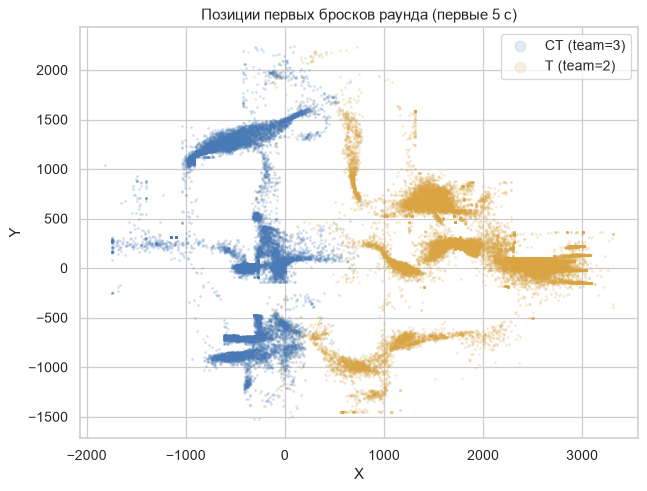

          tp_x    tp_y
side                  
CT    -388.815  19.594
T    1,789.299 129.869


In [5]:
first_tick = throws.groupby(['match_id', 'round'])['start_tick'].transform('min')
early = throws[(throws['start_tick'] - first_tick) < 5 * TICKRATE]
fig, ax = plt.subplots(figsize=(8, 6))
for side, g in early.groupby('side', observed=True):
    s = g.sample(min(len(g), 30000), random_state=0)
    ax.scatter(s['tp_x'], s['tp_y'], s=2, alpha=0.15, label=f'{side} (team={2 if side == "T" else 3})', color=TEAM_COLORS[side])
ax.set_aspect('equal'); ax.legend(markerscale=6)
ax.set_title('Позиции первых бросков раунда (первые 5 с)'); ax.set_xlabel('X'); ax.set_ylabel('Y')
plt.show()
print(early.groupby('side', observed=True)[['tp_x', 'tp_y']].median())

Первые броски команды 2 сгруппированы на востоке карты (большой X), а команды 3 — в центре и на западе. Это соответствует расположению
спавнов T и CT на Cache. Маппинг **2 = T, 3 = CT** подтверждается.

## 2. Анализ по отдельным полям

### 2.1 Тип гранаты и количество бросков в матче

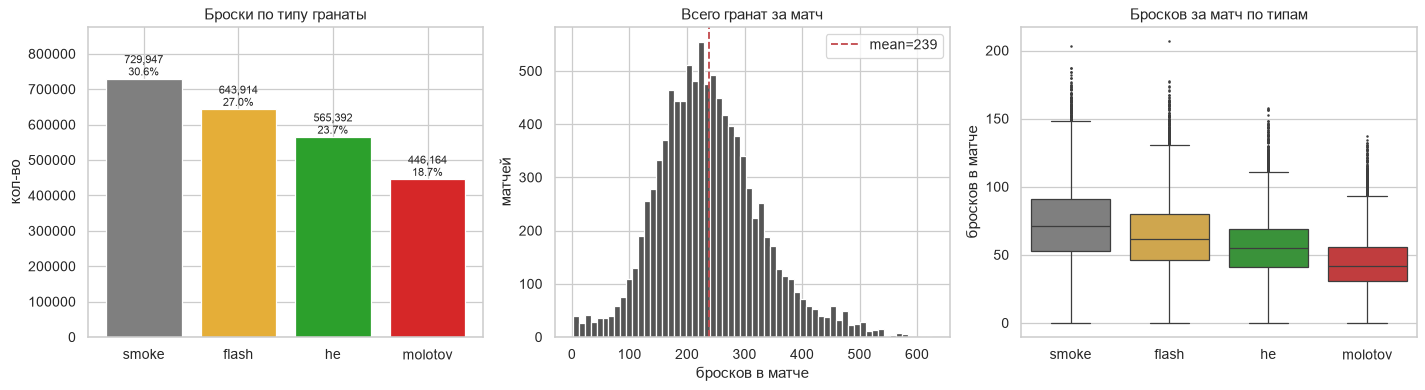

,count,mean,std,min,25%,50%,75%,max
grenade_type,,,,,,,,
smoke,"9,984.000",73.112,29.374,0.000,53.000,71.000,91.000,203.000
flash,"9,984.000",64.495,26.627,0.000,46.000,62.000,80.000,207.000
he,"9,984.000",56.630,22.921,0.000,41.000,55.000,69.000,158.000
molotov,"9,984.000",44.688,19.924,0.000,31.000,42.000,56.000,137.000
total,"9,984.000",238.924,90.858,1.000,178.000,231.000,291.000,626.000


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
vc = throws['grenade_type'].value_counts().reindex(GT_ORDER)
axes[0].bar(vc.index, vc.values, color=[GT_COLORS[g] for g in vc.index])
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f'{v:,}\n{v / vc.sum():.1%}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Броски по типу гранаты'); axes[0].set_ylabel('кол-во'); axes[0].set_ylim(0, vc.max() * 1.2)

per_match = throws.groupby(['match_id', 'grenade_type'], observed=False).size().unstack()
per_match.columns = per_match.columns.astype(str)
per_match['total'] = per_match.sum(axis=1)
axes[1].hist(per_match['total'], bins=60, color='#555')
axes[1].axvline(per_match['total'].mean(), color='r', ls='--', label=f"mean={per_match['total'].mean():.0f}")
axes[1].set_title('Всего гранат за матч'); axes[1].set_xlabel('бросков в матче'); axes[1].set_ylabel('матчей'); axes[1].legend()

sns.boxplot(data=per_match[GT_ORDER].melt(var_name='grenade_type', value_name='n'), x='grenade_type', y='n',
            hue='grenade_type', palette=GT_COLORS, ax=axes[2], fliersize=1, legend=False)
axes[2].set_title('Бросков за матч по типам'); axes[2].set_xlabel(''); axes[2].set_ylabel('бросков в матче')
plt.tight_layout(); plt.show()
per_match.describe().T

### 2.2 Сторона (Team)

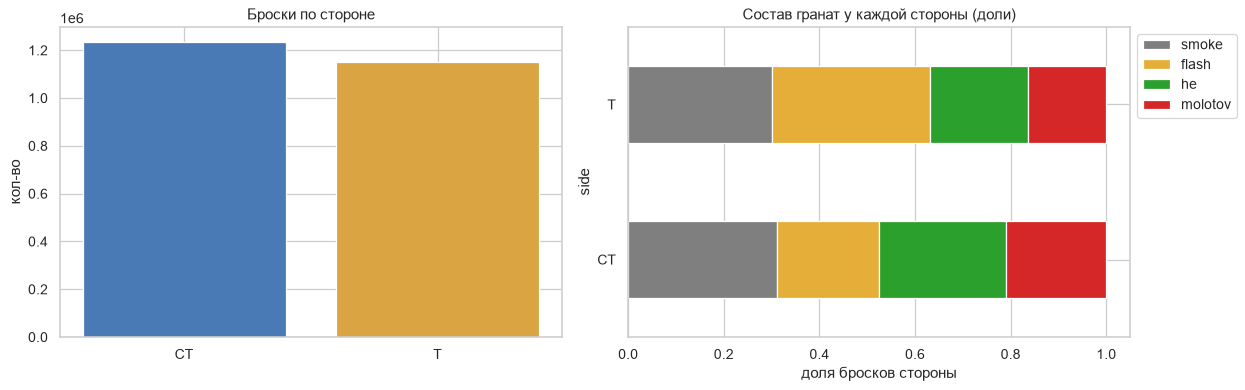

side,CT,T,All
grenade_type,,,
smoke,384672,345275,729947
flash,263585,380329,643914
he,329168,236224,565392
molotov,258574,187590,446164
All,1235999,1149418,2385417


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sc = throws['side'].value_counts()
axes[0].bar(sc.index, sc.values, color=[TEAM_COLORS[s] for s in sc.index])
axes[0].set_title('Броски по стороне'); axes[0].set_ylabel('кол-во')
ct = pd.crosstab(throws['grenade_type'], throws['side'], normalize='columns')
ct.T.plot(kind='barh', stacked=True, color=[GT_COLORS[g] for g in ct.index], ax=axes[1])
axes[1].set_title('Состав гранат у каждой стороны (доли)'); axes[1].set_xlabel('доля бросков стороны')
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
pd.crosstab(throws['grenade_type'], throws['side'], margins=True)

### 2.3 Раунд (`RoundIndexMatch`)
Формат MR12: индексы 0–23 — основное время (0 и 12 — пистолетные раунды), 24 и дальше — овертайм.
`RoundIndexDemo` во всех записях совпадает с `RoundIndexMatch` (см. 1.2), поэтому отдельно его не разбираем.

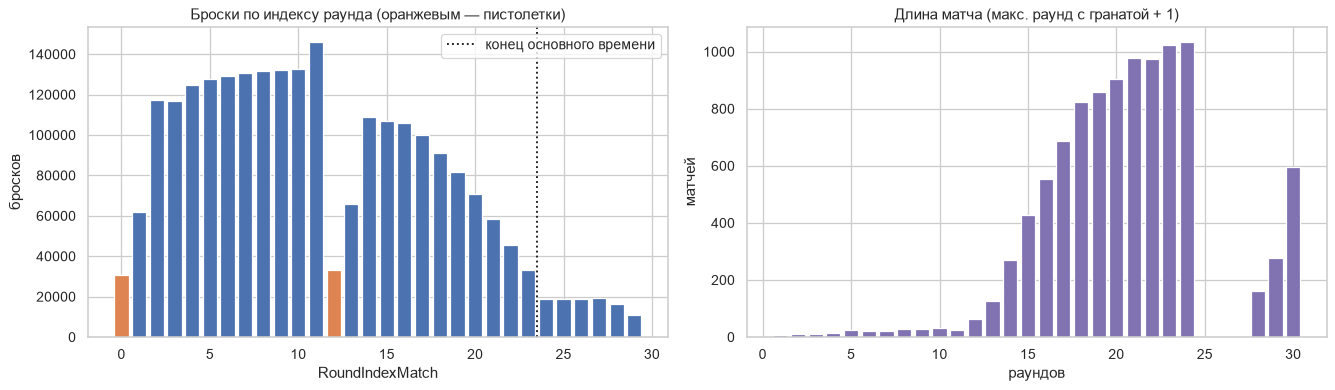

Доля матчей, ушедших в овертайм: 10.3% | матчей короче 13 раундов (сдача/дисконнект): 287


In [8]:
rounds_per_match = throws.groupby('match_id')['round'].max() + 1
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rc = throws['round'].value_counts().sort_index()
axes[0].bar(rc.index, rc.values, color='#4c72b0')
for r in (0, 12):
    axes[0].bar(r, rc.get(r, 0), color='#dd8452')
axes[0].axvline(23.5, color='k', ls=':', label='конец основного времени')
axes[0].set_title('Броски по индексу раунда (оранжевым — пистолетки)'); axes[0].set_xlabel('RoundIndexMatch'); axes[0].set_ylabel('бросков'); axes[0].legend()
rpm = rounds_per_match.value_counts().sort_index()
axes[1].bar(rpm.index, rpm.values, color='#8172b2')
axes[1].set_title('Длина матча (макс. раунд с гранатой + 1)'); axes[1].set_xlabel('раундов'); axes[1].set_ylabel('матчей')
plt.tight_layout(); plt.show()
print('Доля матчей, ушедших в овертайм:', f'{(rounds_per_match > 24).mean():.1%}',
      '| матчей короче 13 раундов (сдача/дисконнект):', (rounds_per_match < 13).sum())

Число бросков падает к поздним раундам в основном потому, что до них доживает всё меньше матчей: при 13:x матч заканчивается раньше 24-го раунда.
Корректная нормировка «гранат на один сыгранный раунд» — в разделе 3.1.

### 2.4 Рейтинг Premier (`PremierRatingNew`)

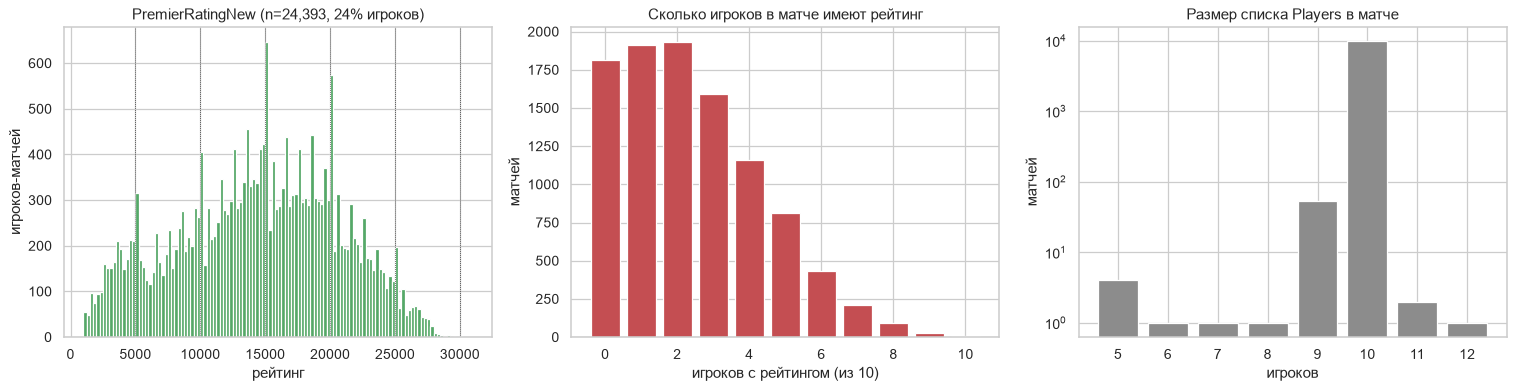

count   24,393.000
mean    14,389.109
std      6,210.368
min      1,000.000
25%      9,886.000
50%     14,766.000
75%     19,120.000
max     30,982.000
Name: rating, dtype: float64

Топ-10 самых частых значений рейтинга:
rating
14,999.000    265
19,999.000    236
9,999.000     165
4,999.000     136
15,000.000    113
20,000.000     96
24,999.000     84
10,000.000     56
5,000.000      39
1,000.000      24
Name: count, dtype: int64


In [9]:
rated = players.dropna(subset=['rating'])
cov = players.groupby('match_id')['rating'].apply(lambda s: s.notna().sum())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(rated['rating'], bins=120, color='#55a868')
axes[0].set_title(f'PremierRatingNew (n={len(rated):,}, {len(rated) / len(players):.0%} игроков)')
axes[0].set_xlabel('рейтинг'); axes[0].set_ylabel('игроков-матчей')
for b in range(5000, 35000, 5000):
    axes[0].axvline(b, color='k', lw=0.6, ls=':')
cv = cov.value_counts().sort_index()
axes[1].bar(cv.index, cv.values, color='#c44e52')
axes[1].set_title('Сколько игроков в матче имеют рейтинг'); axes[1].set_xlabel('игроков с рейтингом (из 10)'); axes[1].set_ylabel('матчей')
psz = players.groupby('match_id').size().value_counts().sort_index()
axes[2].bar(psz.index.astype(str), psz.values, color='#8c8c8c')
axes[2].set_title('Размер списка Players в матче'); axes[2].set_xlabel('игроков'); axes[2].set_ylabel('матчей'); axes[2].set_yscale('log')
plt.tight_layout(); plt.show()
print(rated['rating'].describe())
print('\nТоп-10 самых частых значений рейтинга:')
print(rated['rating'].value_counts().head(10))

Рейтинг есть только у части игроков: его нет в MM-матчах и, судя по всему, у тех, у кого он скрыт или ещё не откалиброван.
Есть заметные пики на значениях вида `x999` и `x000` (9999, 14999, 19999…) — это границы цветовых тиров Premier.
В разрезах «скилл × X» дальше учитываем только игроков с рейтингом и группируем их по тирам по 5000.

### 2.5 Позиция броска (`ThrowPoint.Position`) и высота

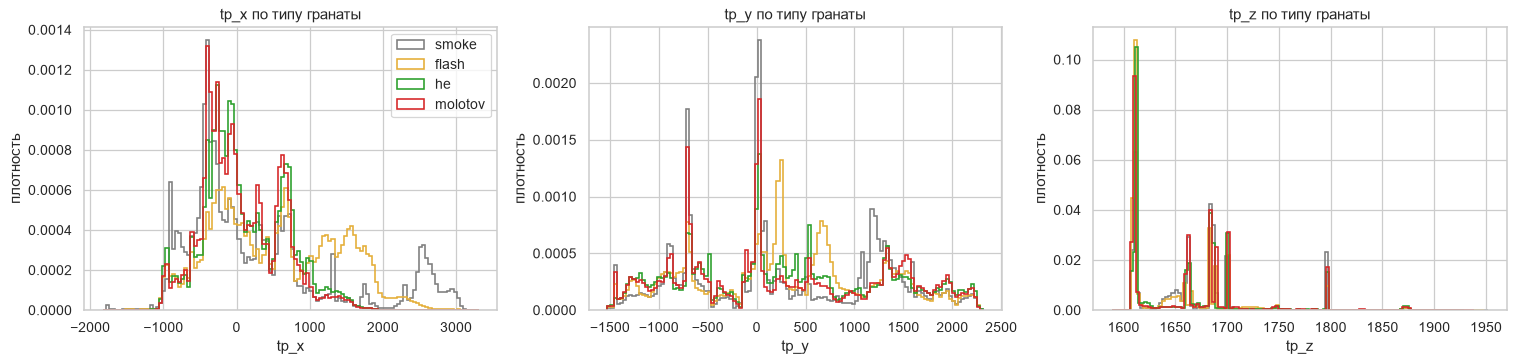

,count,mean,std,min,25%,50%,75%,max
tp_x,"2,385,417.000",267.381,832.465,"-1,827.972",-326.425,40.505,690.144,"3,307.973"
tp_y,"2,385,417.000",293.795,965.266,"-1,526.473",-594.640,190.144,"1,183.291","2,315.969"
tp_z,"2,385,417.000","1,661.150",54.797,"1,588.827","1,612.031","1,660.031","1,688.031","1,951.719"
from_x,"2,385,417.000",269.732,817.407,"-1,833.094",-305.094,48.062,674.125,"3,322.031"
from_y,"2,385,417.000",297.158,962.177,"-1,542.969",-607.688,192.438,"1,194.344","2,319.594"
from_z,"2,385,417.000","1,728.308",52.251,"1,621.312","1,683.500","1,725.312","1,755.562","2,015.969"
to_x,"2,385,417.000",274.203,542.248,"-3,262.875",-144.906,356.781,669.674,"4,986.219"
to_y,"2,385,417.000",362.730,984.829,"-2,763.157",-605.031,255.875,"1,380.250","3,664.914"
to_z,"2,385,417.000","1,695.904",120.076,"1,405.594","1,616.344","1,671.298","1,704.997","3,115.744"


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c in zip(axes, ['tp_x', 'tp_y', 'tp_z']):
    for gt in GT_ORDER:
        ax.hist(throws.loc[throws['grenade_type'] == gt, c], bins=120, histtype='step', lw=1.3, color=GT_COLORS[gt], label=gt, density=True)
    ax.set_title(f'{c} по типу гранаты'); ax.set_xlabel(c); ax.set_ylabel('плотность')
axes[0].legend()
plt.tight_layout(); plt.show()
throws[['tp_x', 'tp_y', 'tp_z', 'from_x', 'from_y', 'from_z', 'to_x', 'to_y', 'to_z']].describe().T

`PosFrom` ≈ `ThrowPoint.Position` + рост до глаз (Z выше примерно на 64), то есть это точка, откуда вылетает снаряд. `PosTo` — точка детонации или остановки.
Пики по `tp_z` соответствуют «этажам» Cache: основной уровень около 1612, а также подъёмы и ящики.

### 2.6 Скорость игрока в момент броска (`ThrowPoint.Velocity`)

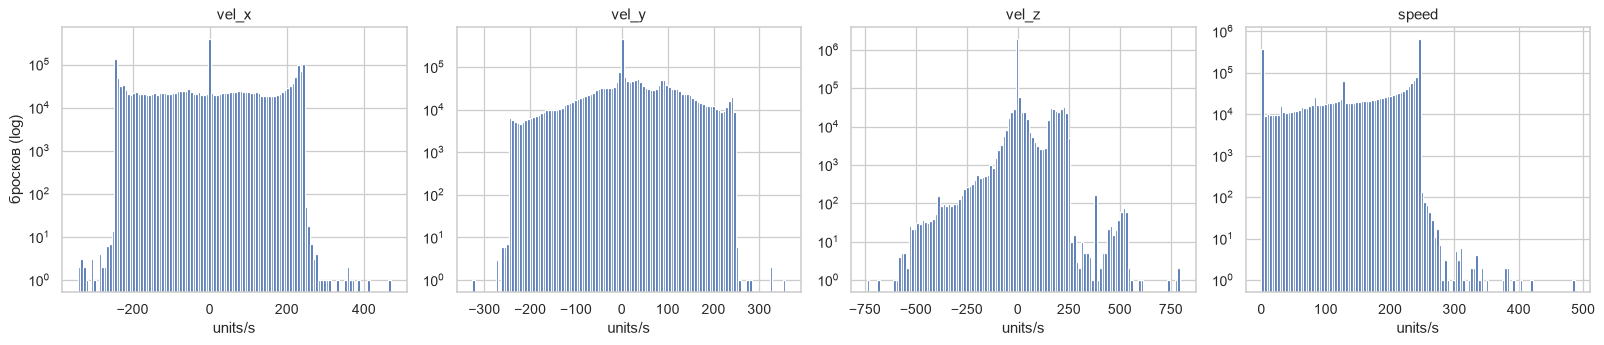

speed,стоит (<5),идёт (5–100),бег/шаг (100–200),бег (200+)
grenade_type,,,,
smoke,17.9%,11.4%,19.2%,51.5%
flash,17.1%,14.1%,19.6%,49.3%
he,12.5%,14.8%,31.5%,41.2%
molotov,13.5%,12.7%,27.8%,46.0%


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['vel_x', 'vel_y', 'vel_z', 'speed']):
    ax.hist(throws[c], bins=120, color='#4c72b0')
    ax.set_title(c); ax.set_xlabel('units/s'); ax.set_yscale('log')
axes[0].set_ylabel('бросков (log)')
plt.tight_layout(); plt.show()
spd_bins = pd.cut(throws['speed'], [-0.1, 5, 100, 200, 400], labels=['стоит (<5)', 'идёт (5–100)', 'бег/шаг (100–200)', 'бег (200+)'])
pd.crosstab(throws['grenade_type'], spd_bins, normalize='index').style.format('{:.1%}').background_gradient(axis=1)

`vel_z` почти всегда равен 0; ненулевые значения дают прыжковые броски (jump-throw). Горизонтальная скорость распределена бимодально:
игрок либо стоит (0), либо бежит (~215–250, это потолок скорости с гранатой в руках).

### 2.7 Угол обзора бросающего (`ViewX` = yaw, `ViewY` = pitch)

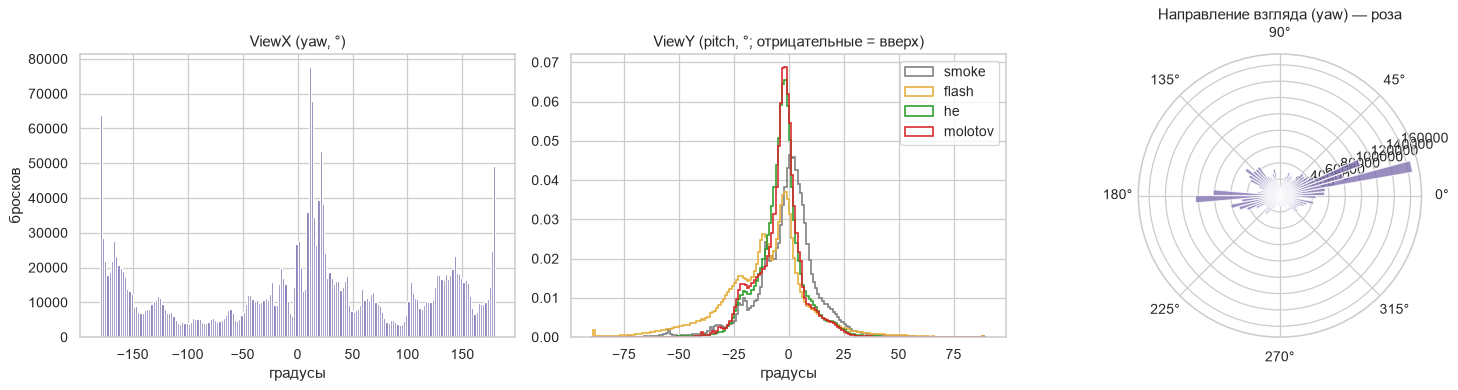

,count,mean,std,min,25%,50%,75%,max
grenade_type,,,,,,,,
smoke,"729,947.000",-0.850,14.880,-89.000,-7.837,0.482,6.468,89.000
flash,"643,914.000",-10.416,20.242,-89.000,-21.274,-8.316,0.164,89.000
he,"565,392.000",-3.720,11.057,-89.000,-8.965,-3.055,1.179,89.000
molotov,"446,164.000",-4.095,10.959,-89.000,-9.485,-2.816,1.182,153.152


In [12]:
fig = plt.figure(figsize=(17, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.hist(throws['view_x'], bins=180, color='#8172b2')
ax1.set_title('ViewX (yaw, °)'); ax1.set_xlabel('градусы'); ax1.set_ylabel('бросков')
ax2 = fig.add_subplot(1, 3, 2)
for gt in GT_ORDER:
    ax2.hist(throws.loc[throws['grenade_type'] == gt, 'view_y'], bins=np.arange(-90, 91, 1), histtype='step', color=GT_COLORS[gt], label=gt, density=True, lw=1.3)
ax2.set_title('ViewY (pitch, °; отрицательные = вверх)'); ax2.set_xlabel('градусы'); ax2.legend()
ax3 = fig.add_subplot(1, 3, 3, projection='polar')
h, edges = np.histogram(np.deg2rad(throws['view_x']), bins=72)
ax3.bar(edges[:-1], h, width=np.diff(edges), align='edge', color='#8172b2', alpha=0.8)
ax3.set_title('Направление взгляда (yaw) — роза')
plt.tight_layout(); plt.show()
throws.groupby('grenade_type', observed=True)['view_y'].describe()

Сильнее всего вверх бросают **флешки** (медиана `ViewY` ≈ −8°, четверть бросков выше −21°): это поп-флешки через стены и крыши.
У смоков медиана около 0°, но разброс широкий: есть и лайнапы вверх, и броски вниз с возвышений. HE и молотовы бросают в среднем чуть выше горизонта.
У молотова встречаются единичные значения `ViewY` > 89° — это артефакт записи. Направления yaw группируются вокруг 0°, ±90° и 180°, то есть вдоль осей карты:
коридоры и проходы на Cache в основном прямоугольные.

### 2.8 Стойка: `IsCrouching`, `IsAirborne`

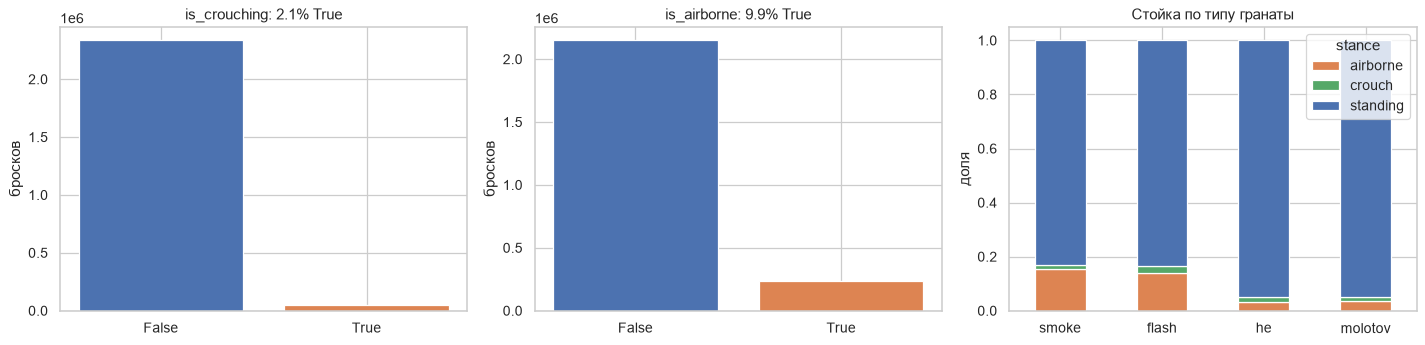

Одновременно crouch & airborne: 5583


stance,airborne,crouch,standing
grenade_type,,,
smoke,15.5%,1.5%,83.0%
flash,14.0%,2.7%,83.3%
he,3.1%,1.9%,95.1%
molotov,3.7%,1.3%,95.0%


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes[:2], ['is_crouching', 'is_airborne']):
    v = throws[c].value_counts()
    ax.bar(v.index.astype(str), v.values, color=['#4c72b0', '#dd8452'][:len(v)])
    ax.set_title(f'{c}: {throws[c].mean():.1%} True'); ax.set_ylabel('бросков')
st = pd.crosstab(throws['grenade_type'], throws['stance'], normalize='index')
st.plot(kind='bar', stacked=True, ax=axes[2], color=['#dd8452', '#55a868', '#4c72b0'])
axes[2].set_title('Стойка по типу гранаты'); axes[2].set_ylabel('доля'); axes[2].set_xlabel(''); axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print('Одновременно crouch & airborne:', int((throws['is_crouching'] & throws['is_airborne']).sum()))
st.style.format('{:.1%}')

### 2.9 Время полёта (`EndTick − StartTick`) и дальность броска

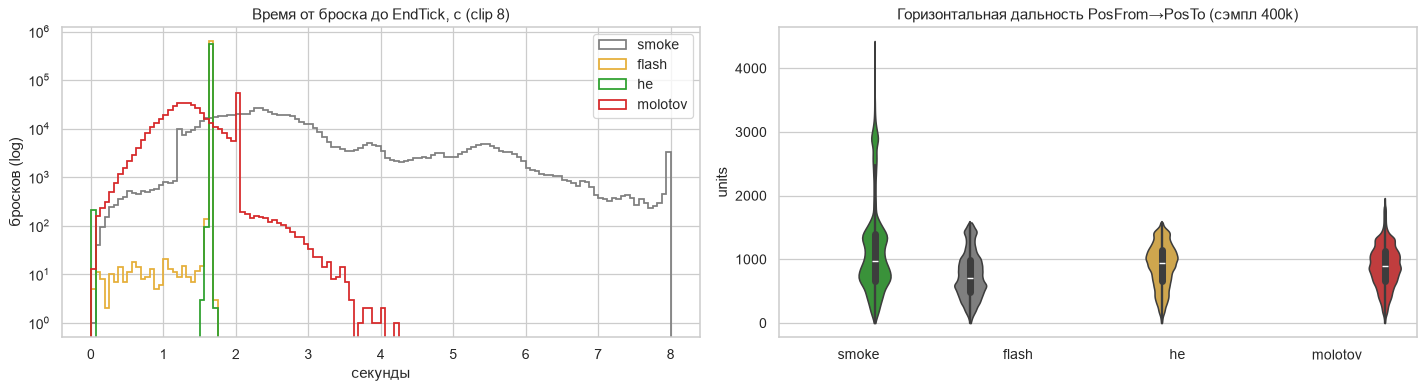

grenade_type           smoke       flash          he     molotov
flight_s   count 729,947.000 643,914.000 565,392.000 446,164.000
           mean        2.853       1.625       1.624       1.369
           std         1.368       0.018       0.031       0.388
           min         0.047       0.016       0.000       0.016
           25%         1.953       1.625       1.625       1.109
           50%         2.453       1.625       1.625       1.328
           75%         3.172       1.625       1.625       1.609
           max        14.531       1.703       1.719       4.203
throw_dist count 729,947.000 643,914.000 565,392.000 446,164.000
           mean    1,141.891     753.458     901.061     890.692
           std       712.179     356.999     341.785     334.828
           min         0.001       0.000       0.000       0.000
           25%       666.774     484.503     656.988     661.158
           50%       970.859     714.007     941.931     893.020
           75%     1,391.218     992.690   1,152.894   1,123.715
           max     4,428.689   1,658.355   1,579.234   1,962.500
throw_dz   count 729,947.000 643,914.000 565,392.000 446,164.000
           mean      -76.343      41.186     -43.291     -52.925
           std        70.173     186.798      80.177      90.385
           min      -368.938    -364.731    -325.700    -327.438
           25%       -98.875     -59.769     -67.932     -81.312
           50%       -65.344     -40.073     -54.434     -64.094
           75%       -52.094      93.762     -32.267     -36.625
           max       842.188   1,138.525   1,104.096   1,247.062

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for gt in GT_ORDER:
    s = throws.loc[throws['grenade_type'] == gt, 'flight_s']
    axes[0].hist(s.clip(upper=8), bins=np.arange(0, 8.05, 0.0625), histtype='step', lw=1.4, color=GT_COLORS[gt], label=gt)
axes[0].set_yscale('log'); axes[0].set_title('Время от броска до EndTick, с (clip 8)'); axes[0].set_xlabel('секунды'); axes[0].set_ylabel('бросков (log)'); axes[0].legend()
sns.violinplot(data=throws.sample(min(len(throws), 400_000), random_state=1), x='grenade_type', y='throw_dist', hue='grenade_type', palette=GT_COLORS,
               order=GT_ORDER, cut=0, ax=axes[1], legend=False)
axes[1].set_title('Горизонтальная дальность PosFrom→PosTo (сэмпл 400k)'); axes[1].set_xlabel(''); axes[1].set_ylabel('units')
plt.tight_layout(); plt.show()
throws.groupby('grenade_type', observed=True)[['flight_s', 'throw_dist', 'throw_dz']].describe().T

- **Флешка и HE**: фиксированный фитиль 1.625 с (104 тика). Значения меньше 1.625 с — редкие случаи, когда раунд закончился раньше или гранату уничтожили.
- **Молотов**: горит с момента приземления, примерно через 0.1–3.5 с. Если граната летит дольше ~2 с, она гаснет в воздухе (в CS2 молотов
  самоуничтожается через 2 с) — это виден как отдельный хвост.
- **Смок**: раскрывается, когда остановится. Медиана около 2.4 с, но длинный хвост до 10+ с — это гранаты, которые катятся или отскакивают.

### 2.10 Урон: HE и огонь (`DamagedPlayers`)

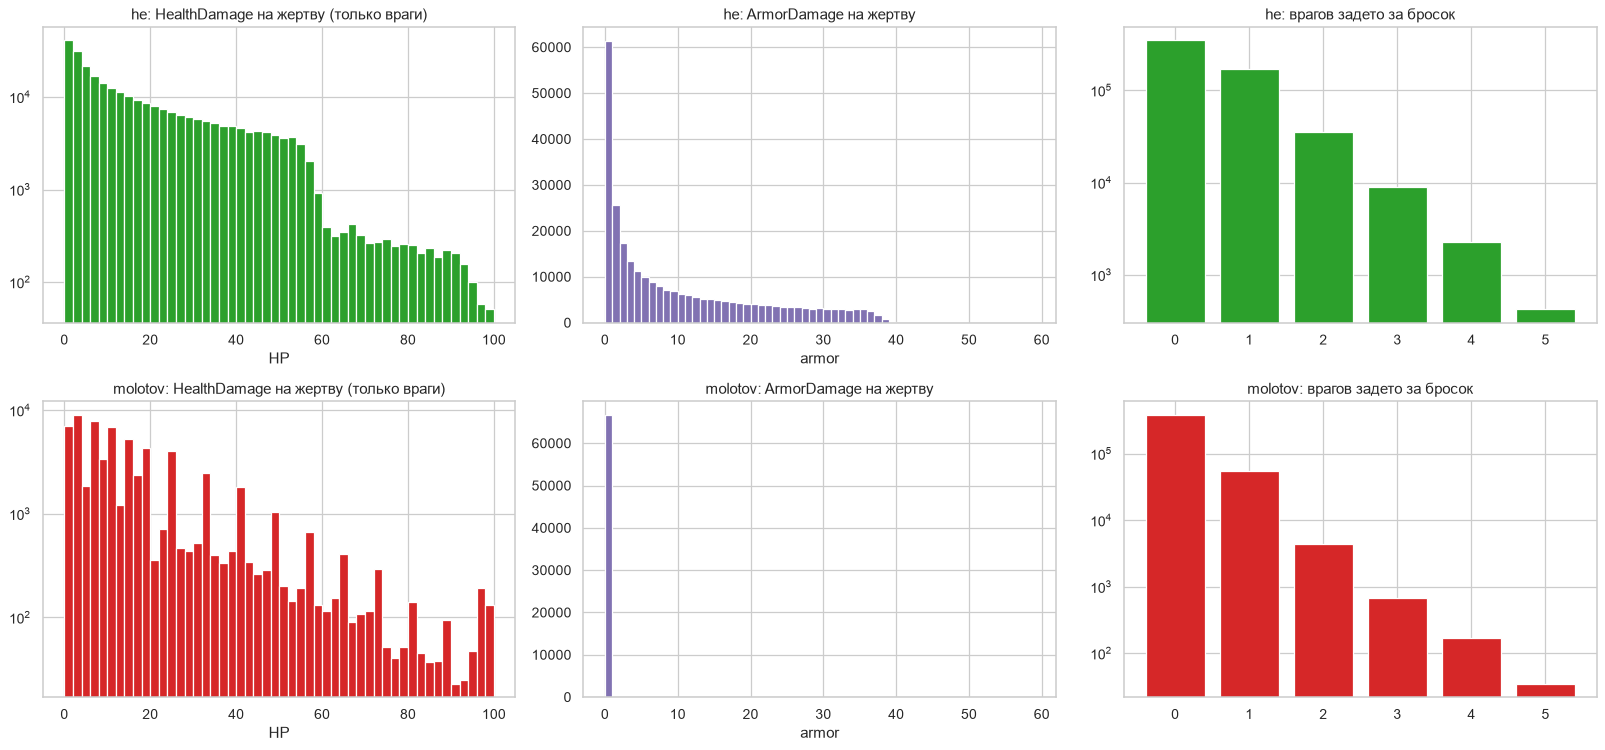

grenade,he,molotov
бросков,"565,392.000","446,164.000"
доля с уроном по врагу,0.367,0.135
ср. урон по врагам/бросок,8.729,2.428
убийств врагов на 100 бросков,2.390,0.933
жертва-событий,"277,937.000","66,587.000"
hits на жертву (медиана),1.000,3.000
WasKilled (доля жертв),0.049,0.063


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
for gt, row in [('he', 0), ('molotov', 1)]:
    d = damage[damage['grenade_type'] == gt]
    axes[row, 0].hist(d['health_dmg'], bins=np.arange(0, 101, 2), color=GT_COLORS[gt])
    axes[row, 0].set_title(f'{gt}: HealthDamage на жертву (только враги)'); axes[row, 0].set_xlabel('HP'); axes[row, 0].set_yscale('log')
    axes[row, 1].hist(d['armor_dmg'], bins=np.arange(0, 60, 1), color='#8172b2')
    axes[row, 1].set_title(f'{gt}: ArmorDamage на жертву'); axes[row, 1].set_xlabel('armor')
    t = throws.loc[throws['grenade_type'] == gt, 'n_enemies_hit'].value_counts().sort_index()
    axes[row, 2].bar(t.index.astype(int).astype(str), t.values, color=GT_COLORS[gt])
    axes[row, 2].set_title(f'{gt}: врагов задето за бросок'); axes[row, 2].set_yscale('log')
plt.tight_layout(); plt.show()

summary = []
for gt in ['he', 'molotov']:
    t = throws[throws['grenade_type'] == gt]
    d = damage[damage['grenade_type'] == gt]
    summary.append({
        'grenade': gt, 'бросков': len(t),
        'доля с уроном по врагу': (t['enemy_dmg'] > 0).mean(),
        'ср. урон по врагам/бросок': t['enemy_dmg'].mean(),
        'убийств врагов на 100 бросков': 100 * t['enemy_kills'].mean(),
        'жертва-событий': len(d), 'hits на жертву (медиана)': d['n_hits'].median(),
        'WasKilled (доля жертв)': d['killed'].mean(),
    })
pd.DataFrame(summary).set_index('grenade').T

Огонь (`Fires.DamagedPlayers`) не упомянут в исходном описании схемы, но он в датасете есть: урон приходит тиками (`n_hits` > 1).
Доля HE, задевших хотя бы одного врага, невелика — большая часть HE используется для давления или «на удачу».

### 2.11 Ослепление: `FlashedPlayers`

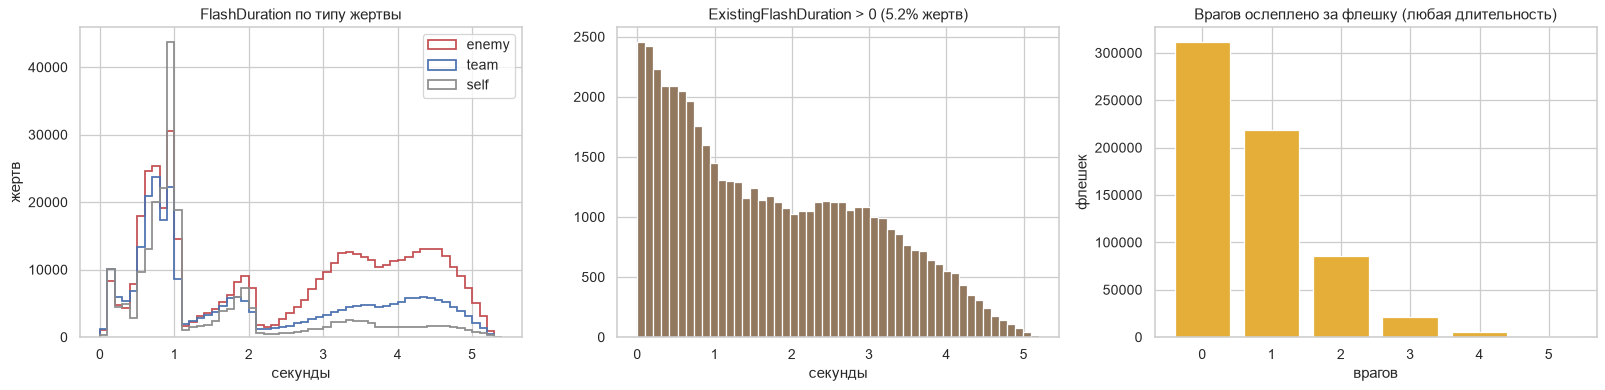

,значение
флешек,643914
флешек без ослеплённых вообще,0.194
"флешек, ослепивших ≥1 врага на ≥2 с",0.337
ср. «вражеские слепые секунды» на флешку,1.949
ср. «свои слепые секунды» на флешку,1.459
доля жертв — враги,0.483
доля жертв — тиммейты,0.290
доля жертв — сам бросивший,0.227
"жертв, убитых пока ослеплены (WasKilled)",0.048
враг убит пока ослеплён (доля вражеских жертв),0.064


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for rel, col in [('enemy', '#c44e52'), ('team', '#4c72b0'), ('self', '#8c8c8c')]:
    axes[0].hist(flashed.loc[flashed['rel'] == rel, 'flash_duration'], bins=np.arange(0, 5.5, 0.1), histtype='step', lw=1.4, color=col, label=rel)
axes[0].set_title('FlashDuration по типу жертвы'); axes[0].set_xlabel('секунды'); axes[0].set_ylabel('жертв'); axes[0].legend()
axes[1].hist(flashed.loc[flashed['flash_existing'] > 0, 'flash_existing'], bins=50, color='#937860')
axes[1].set_title(f"ExistingFlashDuration > 0 ({(flashed['flash_existing'] > 0).mean():.1%} жертв)"); axes[1].set_xlabel('секунды')
nfl = fb['n_enemies_flashed'].value_counts().sort_index()
axes[2].bar(nfl.index.astype(int).astype(str), nfl.values, color=GT_COLORS['flash'])
axes[2].set_title('Врагов ослеплено за флешку (любая длительность)'); axes[2].set_xlabel('врагов'); axes[2].set_ylabel('флешек')
plt.tight_layout(); plt.show()

rel_share = flashed['rel'].value_counts(normalize=True)
pd.Series({
    'флешек': len(fb),
    'флешек без ослеплённых вообще': (fb[['enemy_blind_s', 'team_blind_s', 'self_blind_s']].sum(axis=1) == 0).mean(),
    'флешек, ослепивших ≥1 врага на ≥2 с': (fb['n_enemies_flashed_2s'] > 0).mean(),
    'ср. «вражеские слепые секунды» на флешку': fb['enemy_blind_s'].mean(),
    'ср. «свои слепые секунды» на флешку': fb['team_blind_s'].mean() + fb['self_blind_s'].mean(),
    'доля жертв — враги': rel_share.get('enemy', 0),
    'доля жертв — тиммейты': rel_share.get('team', 0),
    'доля жертв — сам бросивший': rel_share.get('self', 0),
    'жертв, убитых пока ослеплены (WasKilled)': flashed['killed'].mean(),
    'враг убит пока ослеплён (доля вражеских жертв)': flashed.loc[flashed['rel'] == 'enemy', 'killed'].mean(),
    '…из них убил сам бросивший': (flashed.loc[(flashed['rel'] == 'enemy') & flashed['killed'], 'killed_by']
                                   == flashed.loc[(flashed['rel'] == 'enemy') & flashed['killed'], 'thrower_id']).mean(),
    'тиммейт убит пока ослеплён своей флешкой (доля своих жертв)': flashed.loc[flashed['rel'] == 'team', 'killed'].mean(),
}, dtype=object).to_frame('значение')

В `FlashedPlayers` попадают все ослеплённые: и враги, и тиммейты, и сам бросивший. `FlashDurationAdded` почти всегда равен `FlashDuration`.
У флешек `WasKilled` — это не bool, а объект `{By, From, TickNumber, RemainingFlashDuration, OpenKill?}`: «ослеплённого убил игрок `By`,
и на момент смерти ему оставалось N секунд слепоты». Это готовый признак flash-assist, хотя в описании схемы его не было.

### 2.12 Молотовы: `FinalInfernoInfo.ConvexHull3D`

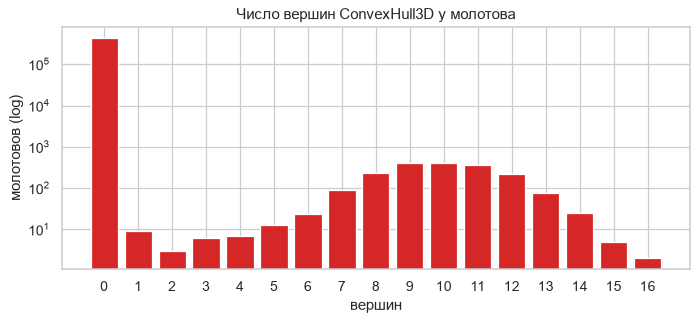

Непустой hull: 0.42% молотовов — площадь огня из этого поля восстановить нельзя.


In [17]:
hv = mo['hull_n_vertices'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(hv.index.astype(int).astype(str), hv.values, color=GT_COLORS['molotov'])
ax.set_yscale('log'); ax.set_title('Число вершин ConvexHull3D у молотова'); ax.set_xlabel('вершин'); ax.set_ylabel('молотовов (log)')
plt.show()
print(f"Непустой hull: {(mo['hull_n_vertices'] > 0).mean():.2%} молотовов — площадь огня из этого поля восстановить нельзя.")

## 3. Комбинации признаков

### 3.1 Тип гранаты × раунд (экономика)
Нормируем на число матчей, в которых этот раунд был сыгран. Получаем «гранат каждого типа на один раунд матча».

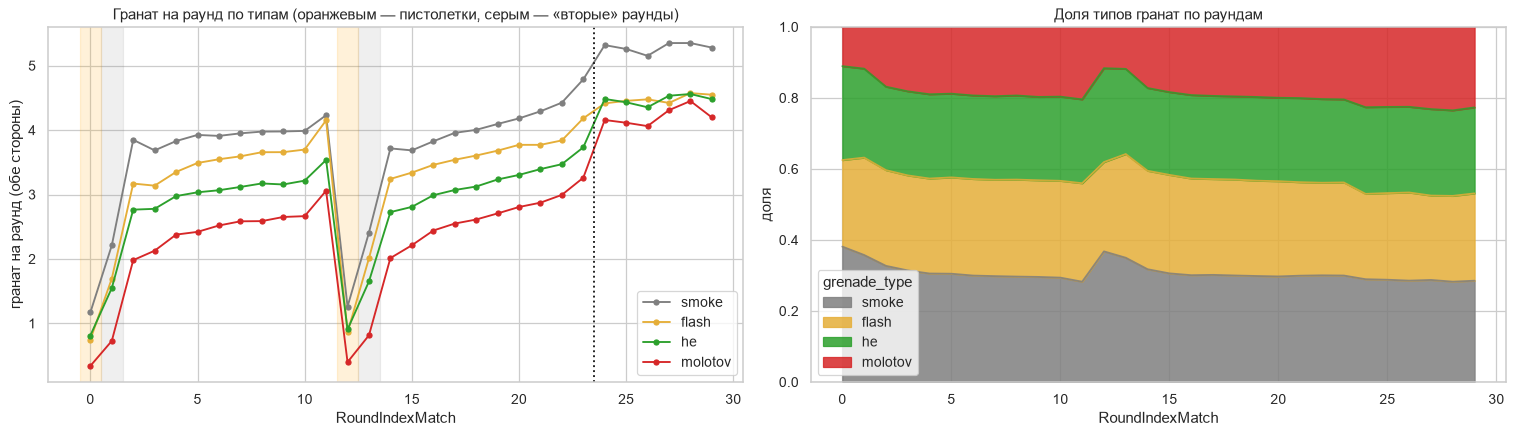

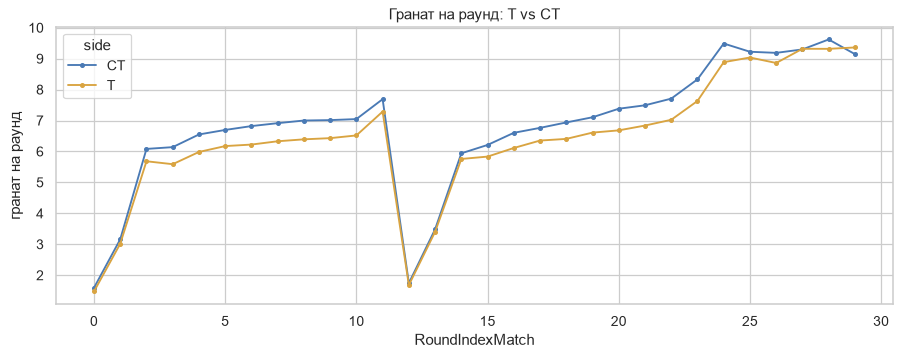

round,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
grenade_type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
smoke,1.170,2.210,3.850,3.690,3.830,3.920,3.910,3.950,3.980,3.980,3.990,4.230,1.260,2.410,3.720,3.690,3.830,3.960,4.000,4.090,4.180,4.290,4.430,4.790,5.320,5.260,5.150,5.350,5.350,5.280
flash,0.750,1.690,3.170,3.140,3.350,3.490,3.550,3.590,3.660,3.660,3.700,4.150,0.860,2.010,3.240,3.340,3.460,3.540,3.600,3.680,3.770,3.770,3.840,4.180,4.420,4.450,4.480,4.420,4.570,4.550
he,0.810,1.550,2.770,2.780,2.980,3.030,3.070,3.120,3.170,3.160,3.220,3.540,0.910,1.650,2.730,2.810,2.990,3.070,3.120,3.230,3.300,3.390,3.470,3.730,4.480,4.430,4.350,4.530,4.560,4.480
molotov,0.340,0.730,1.980,2.130,2.380,2.420,2.520,2.580,2.590,2.650,2.660,3.060,0.400,0.810,2.010,2.210,2.440,2.550,2.610,2.710,2.810,2.870,2.990,3.260,4.160,4.110,4.060,4.310,4.450,4.200


In [18]:
match_rounds = throws.groupby('match_id')['round'].max()
played = pd.Series({r: (match_rounds >= r).sum() for r in range(0, int(match_rounds.max()) + 1)})
by_round = throws.groupby(['round', 'grenade_type'], observed=False).size().unstack()
per_round = by_round.div(played, axis=0)
per_round = per_round[played >= 200]

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for gt in GT_ORDER:
    axes[0].plot(per_round.index, per_round[gt], marker='o', ms=4, color=GT_COLORS[gt], label=gt)
for r in (0, 12):
    axes[0].axvspan(r - 0.5, r + 0.5, color='orange', alpha=0.15)
for r in (1, 13):
    axes[0].axvspan(r - 0.5, r + 0.5, color='grey', alpha=0.12)
axes[0].axvline(23.5, color='k', ls=':')
axes[0].set_title('Гранат на раунд по типам (оранжевым — пистолетки, серым — «вторые» раунды)')
axes[0].set_xlabel('RoundIndexMatch'); axes[0].set_ylabel('гранат на раунд (обе стороны)'); axes[0].legend()
share = per_round.div(per_round.sum(axis=1), axis=0)
share.plot.area(ax=axes[1], color=[GT_COLORS[g] for g in GT_ORDER], alpha=0.85)
axes[1].set_title('Доля типов гранат по раундам'); axes[1].set_xlabel('RoundIndexMatch'); axes[1].set_ylabel('доля'); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

side_round = throws.groupby(['round', 'side'], observed=True).size().unstack().div(played, axis=0)[played >= 200]
ax = side_round.plot(color=TEAM_COLORS, marker='o', ms=3, figsize=(12, 4))
ax.set_title('Гранат на раунд: T vs CT'); ax.set_xlabel('RoundIndexMatch'); ax.set_ylabel('гранат на раунд'); plt.show()
per_round.round(2).T

- В пистолетных раундах (0 и 12) гранат меньше всего: на старте всего 800 $, и их делят между бронёй, пистолетом и утилитой.
- В раундах 1 и 13 видно влияние эко у проигравших пистолетку. Полный закуп наступает к раундам 2–3 и 14–15, дальше число гранат медленно растёт.
- В раундах 11 и 23 (последние раунды половины) — локальный пик: деньги на следующий раунд уже не нужны, поэтому покупают всю утилиту.
- В овертайме (24+) гранат на раунд больше всего, особенно молотовов: у всех много стартовых денег.
- Без данных о результатах раундов и экономике это косвенный вывод, но картина однозначная.

### 3.2 Урон HE против дальности броска и скорости игрока

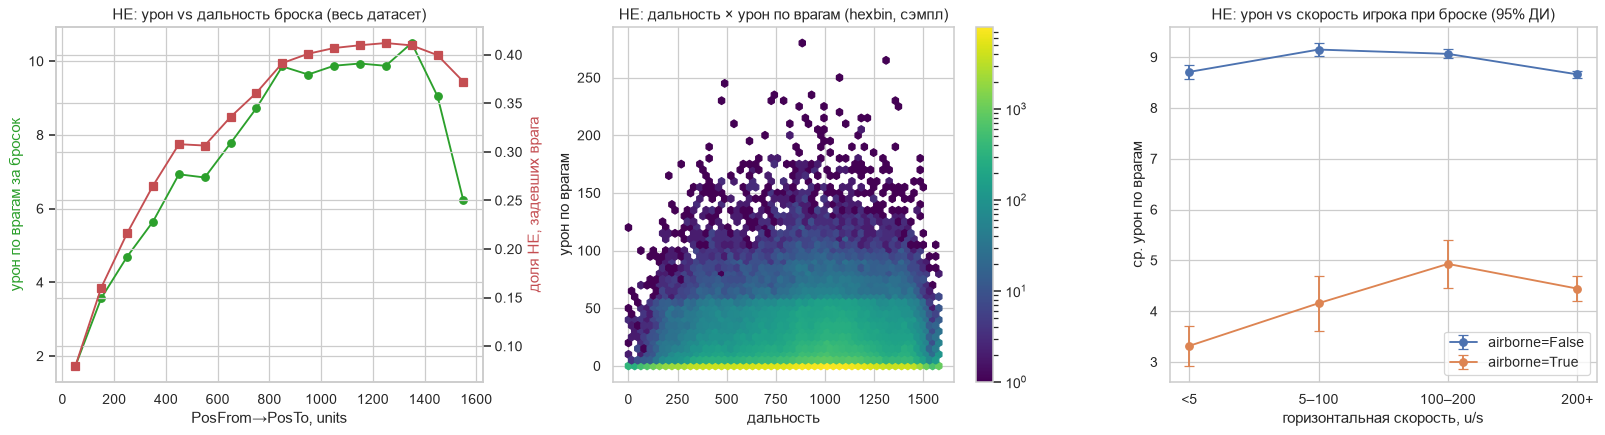

Spearman(дальность, урон по врагам): 0.103 | Spearman(speed, урон): -0.021


In [19]:
he_s = he.sample(min(len(he), 300_000), random_state=2)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
dist_bins = pd.cut(he['throw_dist'], np.arange(0, 2600, 100))
g = he.groupby(dist_bins, observed=True).agg(mean_dmg=('enemy_dmg', 'mean'), hit_rate=('enemy_dmg', lambda s: (s > 0).mean()), n=('enemy_dmg', 'size'))
g = g[g['n'] >= 200]
x = [iv.mid for iv in g.index]
axes[0].plot(x, g['mean_dmg'], marker='o', color='#2ca02c', label='ср. урон по врагам')
ax0b = axes[0].twinx(); ax0b.plot(x, g['hit_rate'], marker='s', color='#c44e52', label='доля с уроном>0'); ax0b.set_ylabel('доля HE, задевших врага', color='#c44e52')
axes[0].set_title('HE: урон vs дальность броска (весь датасет)'); axes[0].set_xlabel('PosFrom→PosTo, units'); axes[0].set_ylabel('урон по врагам за бросок', color='#2ca02c')

hb = axes[1].hexbin(he_s['throw_dist'], he_s['enemy_dmg'], gridsize=50, bins='log', cmap='viridis', mincnt=1)
axes[1].set_title('HE: дальность × урон по врагам (hexbin, сэмпл)'); axes[1].set_xlabel('дальность'); axes[1].set_ylabel('урон по врагам'); fig.colorbar(hb, ax=axes[1])

spd = pd.cut(he['speed'], [-0.1, 5, 100, 200, 400], labels=['<5', '5–100', '100–200', '200+'])
gs = he.groupby([spd, he['is_airborne']], observed=True)['enemy_dmg'].agg(['mean', 'sem', 'size']).reset_index()
for air, sub in gs.groupby('is_airborne'):
    axes[2].errorbar(sub['speed'].astype(str), sub['mean'], yerr=1.96 * sub['sem'], marker='o', capsize=4, label=f'airborne={air}')
axes[2].set_title('HE: урон vs скорость игрока при броске (95% ДИ)'); axes[2].set_xlabel('горизонтальная скорость, u/s'); axes[2].set_ylabel('ср. урон по врагам'); axes[2].legend()
plt.tight_layout(); plt.show()
print('Spearman(дальность, урон по врагам):', stats.spearmanr(he['throw_dist'], he['enemy_dmg']).statistic.round(3),
      '| Spearman(speed, урон):', stats.spearmanr(he['speed'], he['enemy_dmg']).statistic.round(3))

Физику HE лучше всего видно на уровне жертвы — урон в зависимости от расстояния от точки взрыва (`PosTo`) до позиции жертвы:

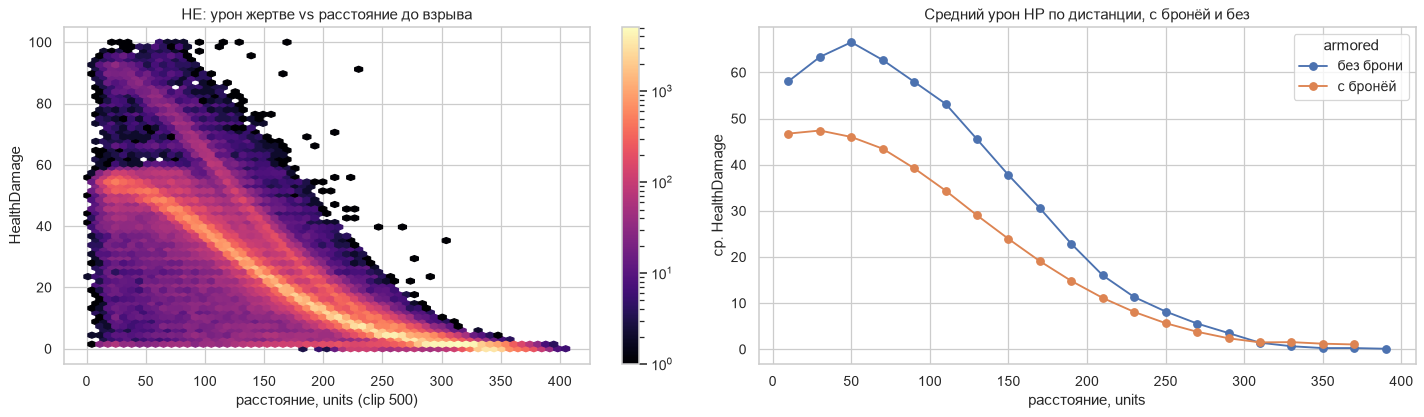

In [20]:
dh = damage[damage['grenade_type'] == 'he'].copy()
dh['dist3d'] = np.sqrt((dh['v_x'] - dh['to_x']) ** 2 + (dh['v_y'] - dh['to_y']) ** 2 + (dh['v_z'] - dh['to_z']) ** 2)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
hb = axes[0].hexbin(dh['dist3d'].clip(upper=500), dh['health_dmg'], gridsize=60, bins='log', cmap='magma', mincnt=1)
fig.colorbar(hb, ax=axes[0])
axes[0].set_title('HE: урон жертве vs расстояние до взрыва'); axes[0].set_xlabel('расстояние, units (clip 500)'); axes[0].set_ylabel('HealthDamage')
dh['armored'] = np.where(dh['armor_dmg'] > 0, 'с бронёй', 'без брони')
gb = dh.groupby([pd.cut(dh['dist3d'], np.arange(0, 420, 20)), 'armored'], observed=True)['health_dmg'].mean().unstack()
gb.index = [iv.mid for iv in gb.index]
gb.plot(ax=axes[1], marker='o'); axes[1].set_title('Средний урон HP по дистанции, с бронёй и без')
axes[1].set_xlabel('расстояние, units'); axes[1].set_ylabel('ср. HealthDamage')
plt.tight_layout(); plt.show()

Чётко видна убывающая функция: отдельные попадания до ~100 HP вблизи эпицентра, средний урон вблизи — 50–70 HP без брони и ~45 HP с бронёй,
а к ~300–350 units урон падает до нуля. Это совпадает с механикой HE в CS2 и подтверждает, что `PosTo` — точка взрыва.
«С бронёй» здесь значит, что у жертвы был `ArmorDamage` > 0 (прокси, другого признака брони в данных нет). От дальности самого броска урон почти не зависит:
важно не насколько далеко бросили, а куда попали.

### 3.3 Длительность ослепления: расстояние и угол взгляда жертвы
Для каждой жертвы считаем:
- расстояние от точки взрыва флешки (`PosTo`) до жертвы;
- угол между направлением взгляда жертвы (`ViewAngle.X` = yaw) и направлением «жертва → взрыв» в горизонтальной плоскости.
  0° — смотрит прямо на флешку, 180° — стоит спиной.

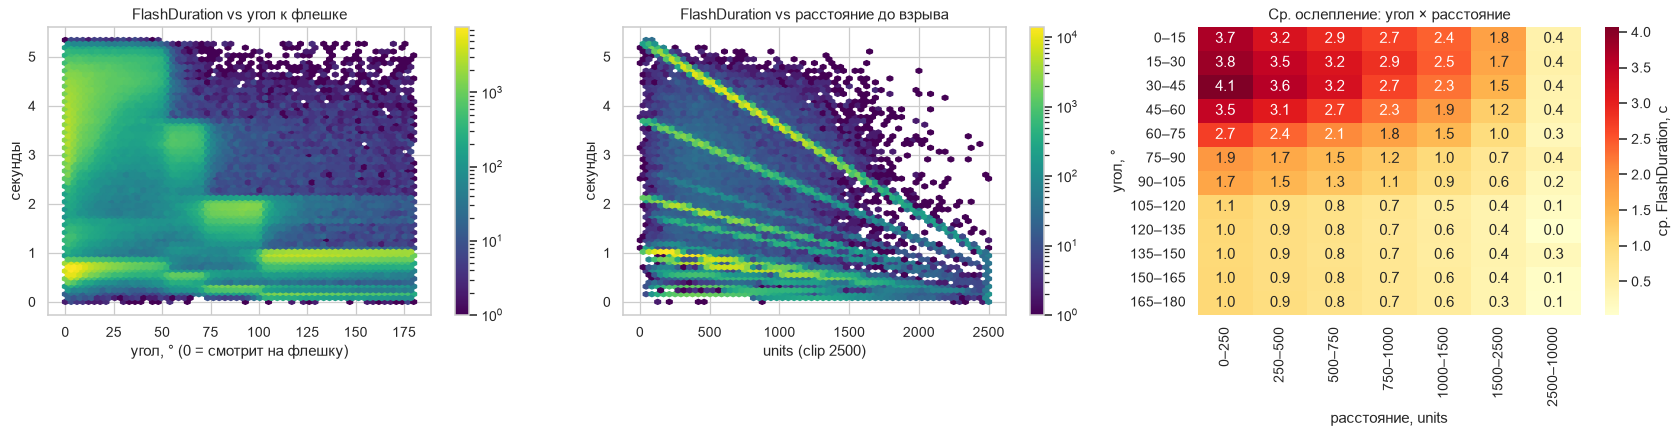

In [21]:
fv = flashed[~((flashed['v_x'] == 0) & (flashed['v_z'] == 0))].copy()
dx, dy, dz = fv['to_x'] - fv['v_x'], fv['to_y'] - fv['v_y'], fv['to_z'] - fv['v_z']
fv['dist'] = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2)
bearing = np.degrees(np.arctan2(dy, dx))
fv['angle'] = np.abs((bearing - fv['va_x'] + 180) % 360 - 180)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
hb = axes[0].hexbin(fv['angle'], fv['flash_duration'], gridsize=60, bins='log', cmap='viridis', mincnt=1)
fig.colorbar(hb, ax=axes[0]); axes[0].set_title('FlashDuration vs угол к флешке'); axes[0].set_xlabel('угол, ° (0 = смотрит на флешку)'); axes[0].set_ylabel('секунды')
hb = axes[1].hexbin(fv['dist'].clip(upper=2500), fv['flash_duration'], gridsize=60, bins='log', cmap='viridis', mincnt=1)
fig.colorbar(hb, ax=axes[1]); axes[1].set_title('FlashDuration vs расстояние до взрыва'); axes[1].set_xlabel('units (clip 2500)'); axes[1].set_ylabel('секунды')
piv = fv.pivot_table(index=pd.cut(fv['angle'], np.arange(0, 181, 15)), columns=pd.cut(fv['dist'], [0, 250, 500, 750, 1000, 1500, 2500, 10000]),
                     values='flash_duration', aggfunc='mean', observed=True)
piv.index = [f'{int(i.left)}–{int(i.right)}' for i in piv.index]
piv.columns = [f'{int(i.left)}–{int(i.right)}' for i in piv.columns]
sns.heatmap(piv, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[2], cbar_kws={'label': 'ср. FlashDuration, с'})
axes[2].set_title('Ср. ослепление: угол × расстояние'); axes[2].set_xlabel('расстояние, units'); axes[2].set_ylabel('угол, °')
plt.tight_layout(); plt.show()

Если жертва смотрит на флешку (угол до ~50°), ослепление в среднем 3–4.5 с. Если стоит спиной, получается короткий фиксированный
минимум (~0.5–1 с). Это механика CS2: полная засветка внутри FOV, частичная — за спиной. С расстоянием ослепление тоже затухает.
Совпадение с механикой подтверждает, что `ViewAngle.X` — это yaw жертвы в момент взрыва.

Сопоставляем угол взгляда бросающего и жертвы — то есть встречаются ли игроки «лицом к лицу»:

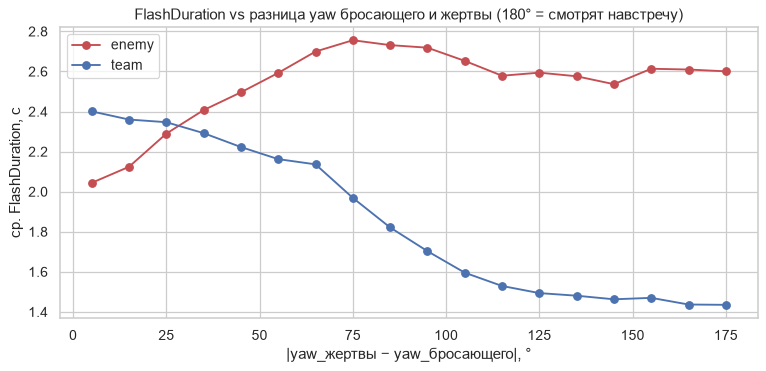

In [22]:
fv = fv.join(throws[['view_x']], on='throw_idx')
fv['rel_yaw'] = np.abs((fv['va_x'] - fv['view_x'] + 180) % 360 - 180)
fig, ax = plt.subplots(figsize=(10, 4.2))
for rel, col in [('enemy', '#c44e52'), ('team', '#4c72b0')]:
    s = fv[fv['rel'] == rel]
    g = s.groupby(pd.cut(s['rel_yaw'], np.arange(0, 181, 10)), observed=True)['flash_duration'].mean()
    ax.plot([iv.mid for iv in g.index], g.values, marker='o', color=col, label=rel)
ax.set_title('FlashDuration vs разница yaw бросающего и жертвы (180° = смотрят навстречу)'); ax.set_xlabel('|yaw_жертвы − yaw_бросающего|, °'); ax.set_ylabel('ср. FlashDuration, с'); ax.legend()
plt.show()

Тиммейты обычно смотрят туда же, куда бросающий (около 0°), и ослепляются слабо. Враги, которые смотрят навстречу (около 180°), ослепляются сильнее всего.
Это ещё одна проверка, которая сходится с механикой и подтверждает, что поля yaw согласованы.

### 3.4 Скилл (`PremierRatingNew`) × использование и эффективность гранат
Берём только пары «игрок–матч» с известным рейтингом и группируем по тирам Premier.

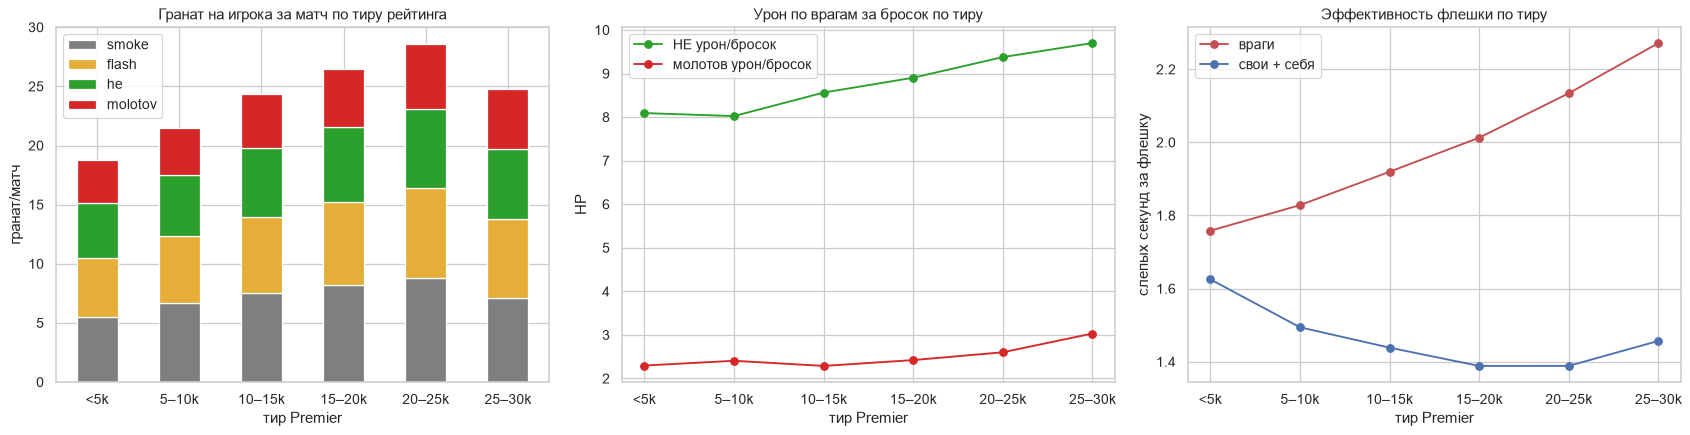

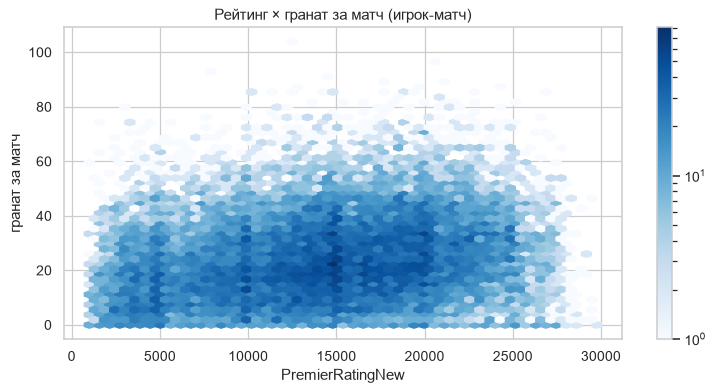

Spearman(rating, гранат/матч): 0.201


,HE: урон по врагам/бросок,Флешка: враж. слепых сек/бросок,Флешка: своих слепых сек/бросок,Молотов: урон по врагам/бросок,игроко-матчей
tier,,,,,
<5k,8.093,1.758,1.625,2.297,2373
5–10k,8.025,1.828,1.494,2.407,4011
10–15k,8.564,1.920,1.438,2.289,6468
15–20k,8.905,2.013,1.388,2.422,6795
20–25k,9.378,2.134,1.389,2.602,3976
25–30k,9.701,2.272,1.457,3.032,767


In [23]:
tier_bins = [0, 5000, 10000, 15000, 20000, 25000, 30000, 40000]
tier_labels = ['<5k', '5–10k', '10–15k', '15–20k', '20–25k', '25–30k', '30k+']
pm = throws.groupby(['match_id', 'thrower_id', 'grenade_type'], observed=False).size().unstack(fill_value=0)
pm.columns = pm.columns.astype(str)
pm['total'] = pm.sum(axis=1)
pp = players.dropna(subset=['rating']).drop_duplicates(['match_id', 'player_id']).rename(columns={'player_id': 'thrower_id'}).set_index(['match_id', 'thrower_id'])
pp = pp.join(pm, how='left').fillna({c: 0 for c in GT_ORDER + ['total']})
pp['tier'] = pd.cut(pp['rating'], tier_bins, labels=tier_labels, right=False)

# эффективность по броскам: присоединяем рейтинг к каждому броску
rmap = players.dropna(subset=['rating']).drop_duplicates(['match_id', 'player_id']).set_index(['match_id', 'player_id'])['rating']
thr_r = throws.join(rmap.rename('rating'), on=['match_id', 'thrower_id'])
thr_r = thr_r[thr_r['rating'].notna()]
thr_r['tier'] = pd.cut(thr_r['rating'], tier_bins, labels=tier_labels, right=False)
eff_t = pd.DataFrame({
    'HE: урон по врагам/бросок': thr_r[thr_r['grenade_type'] == 'he'].groupby('tier', observed=True)['enemy_dmg'].mean(),
    'Флешка: враж. слепых сек/бросок': thr_r[thr_r['grenade_type'] == 'flash'].groupby('tier', observed=True)['enemy_blind_s'].mean(),
    'Флешка: своих слепых сек/бросок': thr_r[thr_r['grenade_type'] == 'flash'].groupby('tier', observed=True).apply(lambda d: (d['team_blind_s'] + d['self_blind_s']).mean()),
    'Молотов: урон по врагам/бросок': thr_r[thr_r['grenade_type'] == 'molotov'].groupby('tier', observed=True)['enemy_dmg'].mean(),
    'игроко-матчей': pp.groupby('tier', observed=True).size(),
})
eff_t = eff_t[eff_t['игроко-матчей'] >= 100]
pp = pp[pp['tier'].isin(eff_t.index)]
pp['tier'] = pp['tier'].cat.remove_unused_categories()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
pp.groupby('tier', observed=True)[GT_ORDER].mean().plot(kind='bar', stacked=True, color=[GT_COLORS[g] for g in GT_ORDER], ax=axes[0])
axes[0].set_title('Гранат на игрока за матч по тиру рейтинга'); axes[0].set_xlabel('тир Premier'); axes[0].set_ylabel('гранат/матч'); axes[0].tick_params(axis='x', rotation=0)
axes[1].plot(eff_t.index.astype(str), eff_t['HE: урон по врагам/бросок'], marker='o', color=GT_COLORS['he'], label='HE урон/бросок')
axes[1].plot(eff_t.index.astype(str), eff_t['Молотов: урон по врагам/бросок'], marker='o', color=GT_COLORS['molotov'], label='молотов урон/бросок')
axes[1].set_title('Урон по врагам за бросок по тиру'); axes[1].set_xlabel('тир Premier'); axes[1].set_ylabel('HP'); axes[1].legend()
axes[2].plot(eff_t.index.astype(str), eff_t['Флешка: враж. слепых сек/бросок'], marker='o', color='#c44e52', label='враги')
axes[2].plot(eff_t.index.astype(str), eff_t['Флешка: своих слепых сек/бросок'], marker='o', color='#4c72b0', label='свои + себя')
axes[2].set_title('Эффективность флешки по тиру'); axes[2].set_xlabel('тир Premier'); axes[2].set_ylabel('слепых секунд за флешку'); axes[2].legend()
plt.tight_layout(); plt.show()

s = pp.sample(min(len(pp), 100_000), random_state=3)
fig, ax = plt.subplots(figsize=(10, 4.5))
hb = ax.hexbin(s['rating'], s['total'], gridsize=50, cmap='Blues', bins='log', mincnt=1); fig.colorbar(hb, ax=ax)
ax.set_title('Рейтинг × гранат за матч (игрок-матч)'); ax.set_xlabel('PremierRatingNew'); ax.set_ylabel('гранат за матч')
plt.show()
print('Spearman(rating, гранат/матч):', stats.spearmanr(pp['rating'], pp['total']).statistic.round(3))
eff_t

С ростом рейтинга (до тира 20–25k) растёт число гранат на игрока — примерно с 19 до 28 за матч. На 25–30k число немного падает, но выборка там маленькая.
Эффективность растёт монотонно: слепых секунд у врагов за флешку — с 1.76 до 2.27, урона HE за бросок — с 8.1 до 9.7.
При этом «своих слепых секунд» становится меньше: эта ошибка чаще встречается у низких тиров, и это прямой кандидат на подсказку пользователю.
Эффект умеренный (Spearman rating × гранат/матч ≈ 0.2), но монотонный. Тир 30k+ скрыт: в нём единицы наблюдений.
Оговорка: рейтинг известен только у ~24% игроков, и выборка смещена к тем, у кого он виден.

### 3.5 Карта: базовая подложка и плотность точек броска
Радара Cache у нас нет, поэтому подложку строим из самих данных: логарифмическая плотность всех позиций игроков
(точки бросков и позиции жертв). Она даёт силуэт проходимой части карты.

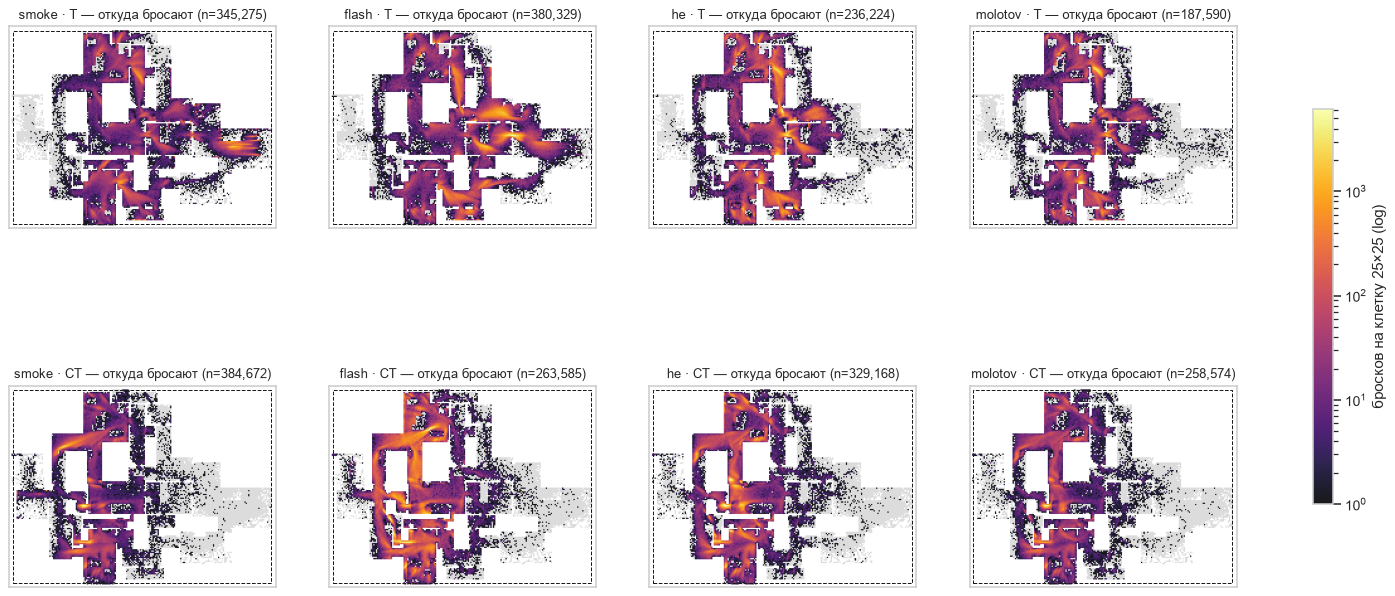

In [24]:
XLIM, YLIM = (-1900, 3400), (-1600, 2400)
EXTENT = [XLIM[0], XLIM[1], YLIM[0], YLIM[1]]
BINS = (np.arange(XLIM[0], XLIM[1] + 1, 25), np.arange(YLIM[0], YLIM[1] + 1, 25))
bg_x = np.concatenate([throws['tp_x'].values, damage['v_x'].values, fv['v_x'].values])
bg_y = np.concatenate([throws['tp_y'].values, damage['v_y'].values, fv['v_y'].values])
BG, _, _ = np.histogram2d(bg_x, bg_y, bins=BINS)
BG = (BG > 0).astype(float)


def map_ax(ax, title=''):
    ax.imshow(BG.T, origin='lower', extent=EXTENT, cmap='Greys', alpha=0.25, vmin=0, vmax=1.6)
    ax.add_patch(plt.Rectangle((-1828, -1526), 3308 + 1828, 2316 + 1526, fill=False, ls='--', lw=0.8, ec='k'))
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_aspect('equal')
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])


def density(ax, x, y, title, cmap='inferno'):
    H, _, _ = np.histogram2d(x, y, bins=BINS)
    H[H == 0] = np.nan
    map_ax(ax, title)
    return ax.imshow(H.T, origin='lower', extent=EXTENT, cmap=cmap, norm=LogNorm(), alpha=0.9)


fig, axes = plt.subplots(2, 4, figsize=(22, 9.5))
for j, gt in enumerate(GT_ORDER):
    for i, side in enumerate(['T', 'CT']):
        d = throws[(throws['grenade_type'] == gt) & (throws['side'] == side)]
        im = density(axes[i, j], d['tp_x'], d['tp_y'], f'{gt} · {side} — откуда бросают (n={len(d):,})')
fig.colorbar(im, ax=axes, shrink=0.6, label='бросков на клетку 25×25 (log)')
plt.show()

Куда прилетают гранаты (`PosTo`) — те же разрезы. Для смоков это фактически карта «стандартных смоков» Cache.

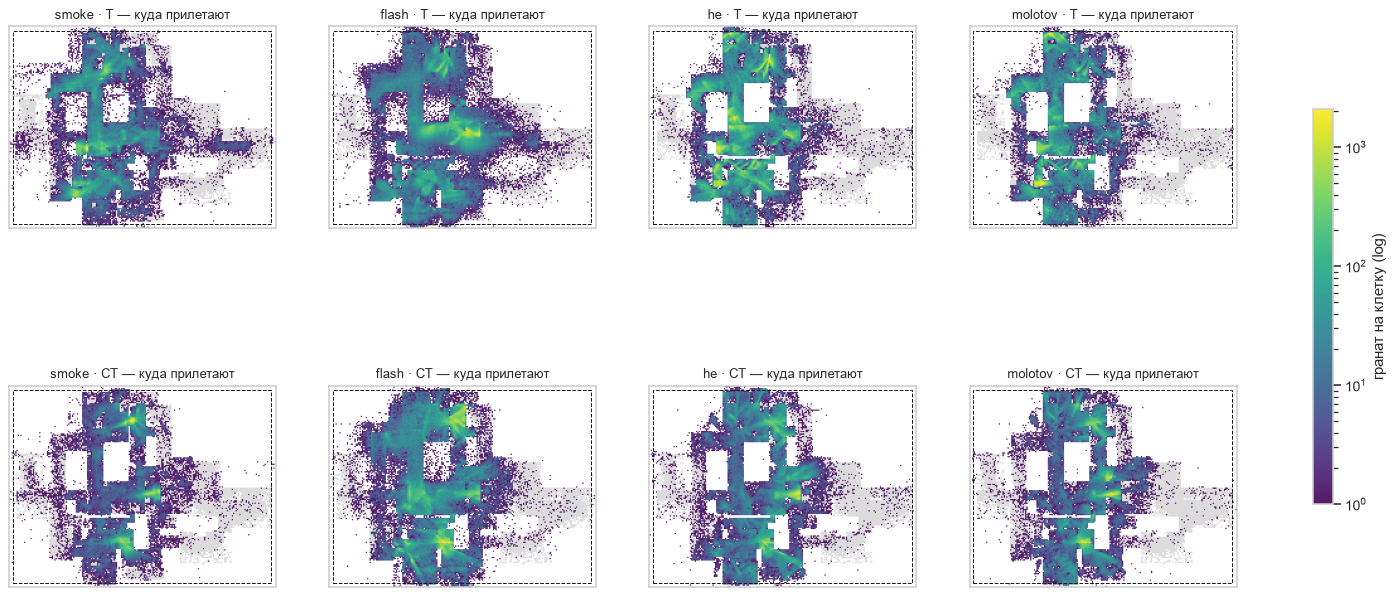

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9.5))
for j, gt in enumerate(GT_ORDER):
    for i, side in enumerate(['T', 'CT']):
        d = throws[(throws['grenade_type'] == gt) & (throws['side'] == side)]
        im = density(axes[i, j], d['to_x'], d['to_y'], f'{gt} · {side} — куда прилетают', cmap='viridis')
fig.colorbar(im, ax=axes, shrink=0.6, label='гранат на клетку (log)')
plt.show()

### 3.6 Сторона × тип гранаты × зона карты
Названий зон (callouts) в датасете нет, поэтому делим карту на сетку 400×400 units и смотрим, кто доминирует в каждой клетке.

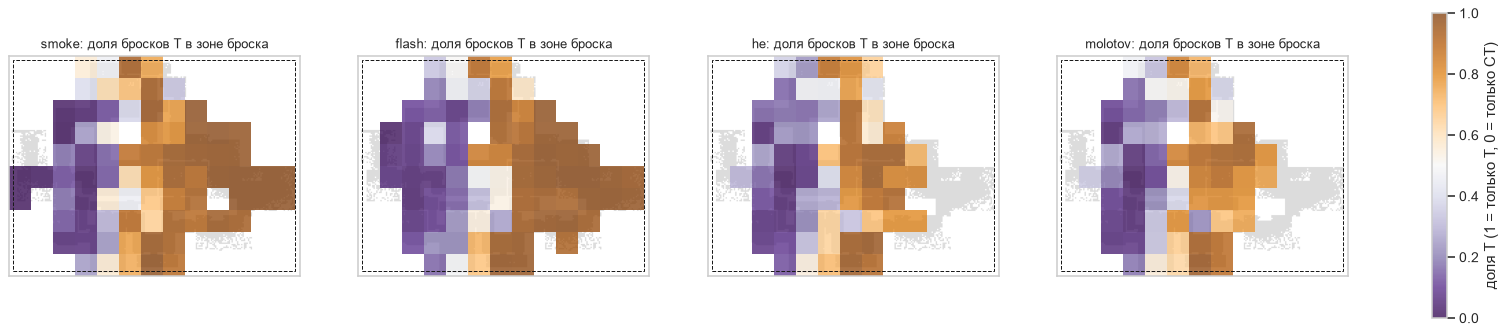

,side,grenade_type,zone_center,n
149,CT,smoke,"(-500.0, 200.0)",52889
101,CT,smoke,"(-900.0, 1000.0)",51696
173,CT,smoke,"(-500.0, 1400.0)",38749
254,CT,flash,"(-100.0, 1400.0)",20974
134,CT,flash,"(-500.0, -600.0)",16945
326,CT,flash,"(300.0, 1400.0)",14803
231,CT,he,"(-100.0, 200.0)",35128
239,CT,he,"(-100.0, 600.0)",30445
151,CT,he,"(-500.0, 200.0)",24613
152,CT,molotov,"(-500.0, 200.0)",32665


In [26]:
ZONE = 400
throws['zone_x'] = ((throws['tp_x'] - XLIM[0]) // ZONE).astype('int16')
throws['zone_y'] = ((throws['tp_y'] - YLIM[0]) // ZONE).astype('int16')
nzx, nzy = int(np.ceil((XLIM[1] - XLIM[0]) / ZONE)), int(np.ceil((YLIM[1] - YLIM[0]) / ZONE))

fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
for ax, gt in zip(axes, GT_ORDER):
    d = throws[throws['grenade_type'] == gt]
    z = d.groupby(['zone_x', 'zone_y']).agg(n=('side', 'size'), t_share=('team', lambda s: (s == 2).mean()))
    M = np.full((nzx, nzy), np.nan)
    zz = z[z['n'] >= 100]
    M[zz.index.get_level_values(0), zz.index.get_level_values(1)] = zz['t_share']
    map_ax(ax, f'{gt}: доля бросков T в зоне броска')
    im = ax.imshow(M.T, origin='lower', extent=[XLIM[0], XLIM[0] + nzx * ZONE, YLIM[0], YLIM[0] + nzy * ZONE], cmap='PuOr_r', vmin=0, vmax=1, alpha=0.75)
fig.colorbar(im, ax=axes, shrink=0.8, label='доля T (1 = только T, 0 = только CT)')
plt.show()

top_zones = (throws.groupby(['zone_x', 'zone_y', 'side', 'grenade_type'], observed=True).size()
             .rename('n').reset_index().sort_values('n', ascending=False))
top_zones['zone_center'] = list(zip(XLIM[0] + (top_zones['zone_x'] + 0.5) * ZONE, YLIM[0] + (top_zones['zone_y'] + 0.5) * ZONE))
top_zones.groupby(['side', 'grenade_type'], observed=True).head(3).sort_values(['side', 'grenade_type'])[['side', 'grenade_type', 'zone_center', 'n']]

### 3.7 Тепловая карта эффективности по зоне броска
Для каждой клетки 100×100 по точке броска считаем среднюю эффективность. Клетки с числом бросков меньше 50 скрыты.

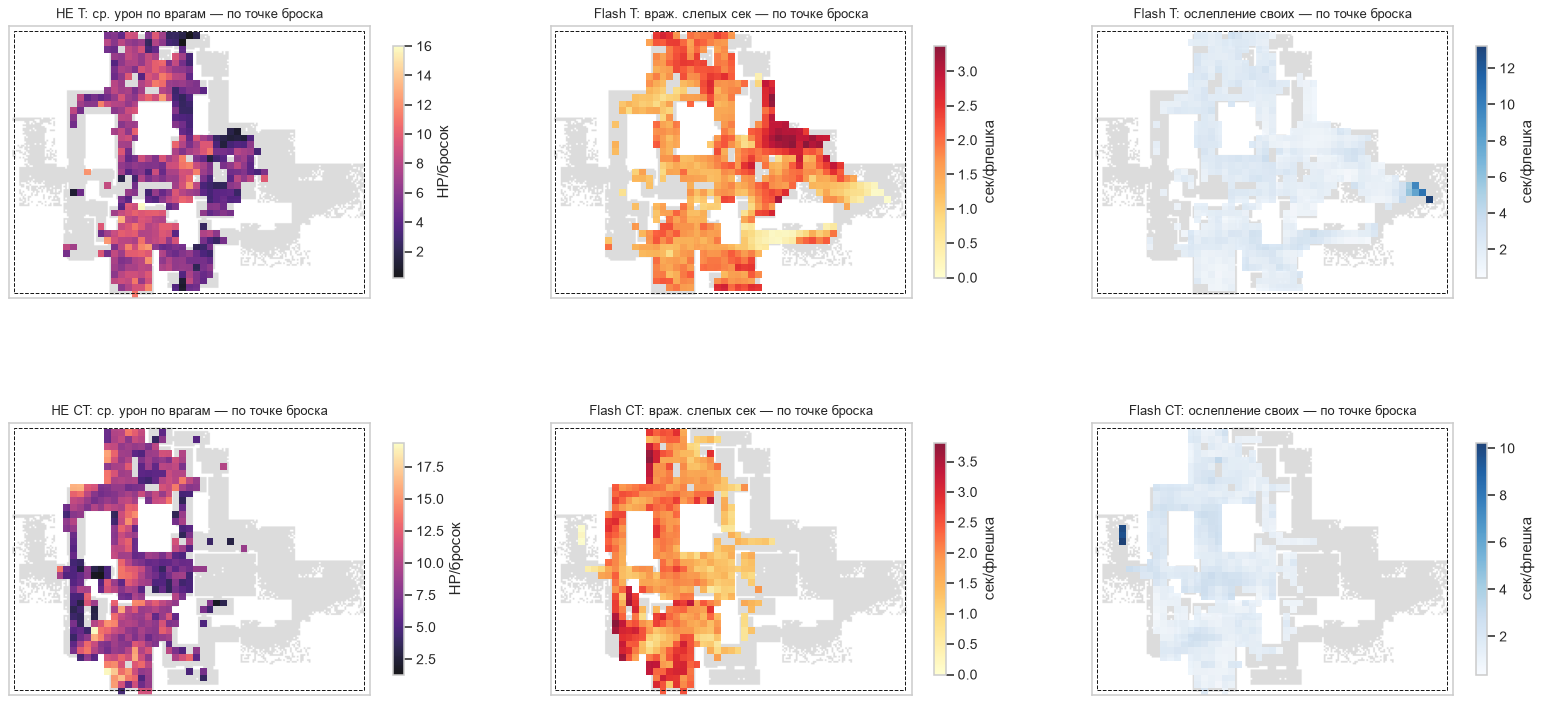

In [27]:
EFF_BINS = (np.arange(XLIM[0], XLIM[1] + 1, 100), np.arange(YLIM[0], YLIM[1] + 1, 100))


def eff_map(ax, d, xcol, ycol, val, title, min_n=50, cmap='magma'):
    st = stats.binned_statistic_2d(d[xcol], d[ycol], d[val], statistic='mean', bins=EFF_BINS)
    cnt = stats.binned_statistic_2d(d[xcol], d[ycol], None, statistic='count', bins=EFF_BINS).statistic
    M = np.where(cnt >= min_n, st.statistic, np.nan)
    map_ax(ax, title)
    return ax.imshow(M.T, origin='lower', extent=EXTENT, cmap=cmap, alpha=0.9)


fig, axes = plt.subplots(2, 3, figsize=(22, 10.5))
for i, side in enumerate(['T', 'CT']):
    im = eff_map(axes[i, 0], he[he['side'] == side], 'tp_x', 'tp_y', 'enemy_dmg', f'HE {side}: ср. урон по врагам — по точке броска')
    fig.colorbar(im, ax=axes[i, 0], shrink=0.7, label='HP/бросок')
    im = eff_map(axes[i, 1], fb[fb['side'] == side], 'tp_x', 'tp_y', 'enemy_blind_s', f'Flash {side}: враж. слепых сек — по точке броска', cmap='YlOrRd')
    fig.colorbar(im, ax=axes[i, 1], shrink=0.7, label='сек/флешка')
    fb_side = fb[fb['side'] == side].assign(own_blind=lambda d: d['team_blind_s'] + d['self_blind_s'])
    im = eff_map(axes[i, 2], fb_side, 'tp_x', 'tp_y', 'own_blind', f'Flash {side}: ослепление своих — по точке броска', cmap='Blues')
    fig.colorbar(im, ax=axes[i, 2], shrink=0.7, label='сек/флешка')
plt.show()

То же, но по **точке детонации**: где флешка или HE реально срабатывают лучше всего.

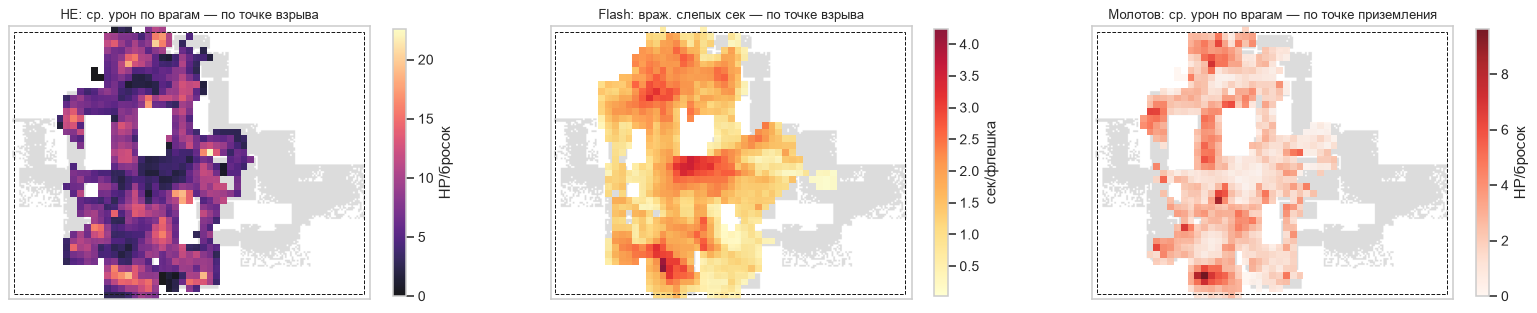

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
im = eff_map(axes[0], he, 'to_x', 'to_y', 'enemy_dmg', 'HE: ср. урон по врагам — по точке взрыва')
fig.colorbar(im, ax=axes[0], shrink=0.7, label='HP/бросок')
im = eff_map(axes[1], fb, 'to_x', 'to_y', 'enemy_blind_s', 'Flash: враж. слепых сек — по точке взрыва', cmap='YlOrRd')
fig.colorbar(im, ax=axes[1], shrink=0.7, label='сек/флешка')
im = eff_map(axes[2], mo, 'to_x', 'to_y', 'enemy_dmg', 'Молотов: ср. урон по врагам — по точке приземления', cmap='Reds')
fig.colorbar(im, ax=axes[2], shrink=0.7, label='HP/бросок')
plt.show()

Эффективность распределена по карте неравномерно: есть отдельные «горячие» клетки — устойчивые точки бросков с высоким средним уроном
или ослеплением. Это готовая основа для фичи «лучшие лайнапы на Cache по данным, а не по видео».

### 3.8 Стойка (crouch/airborne) и скорость × успешность

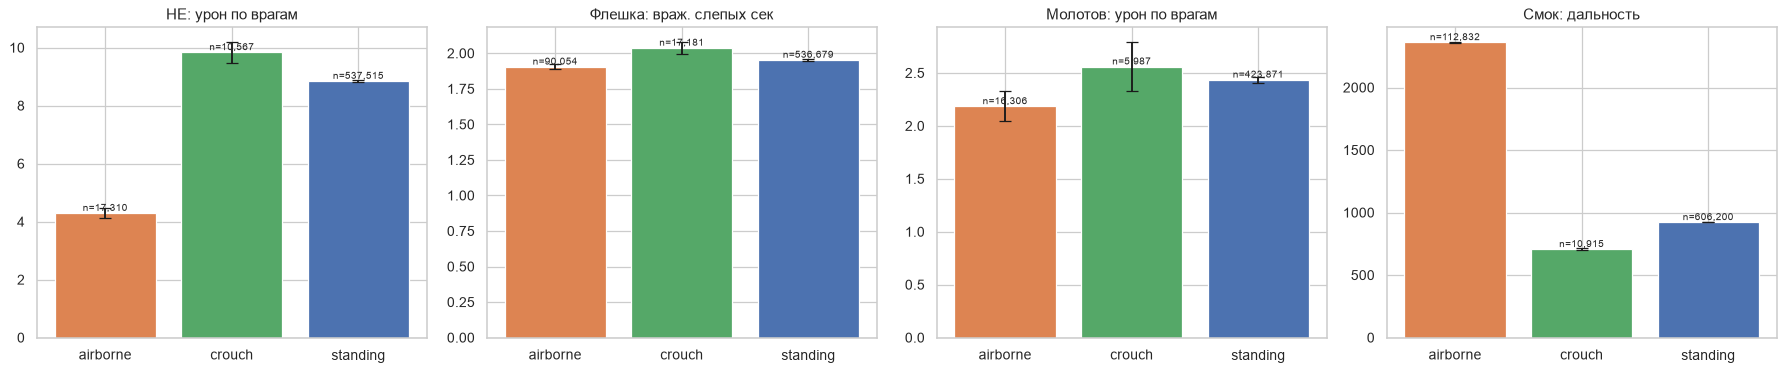

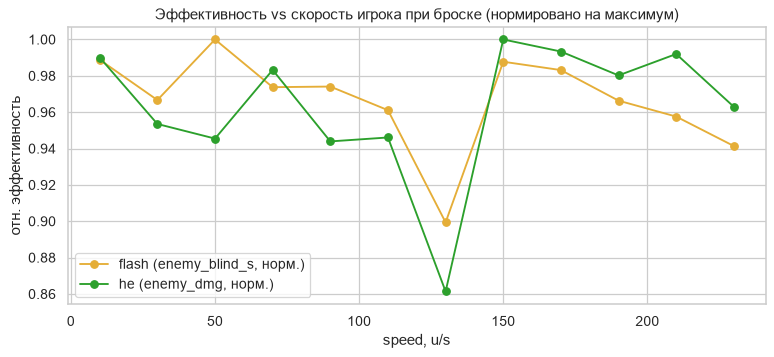

mean                                                                                size                                                                 
metric   HE: урон по врагам Молотов: урон по врагам Смок: дальность Флешка: враж. слепых сек HE: урон по врагам Молотов: урон по врагам Смок: дальность Флешка: враж. слепых сек
stance                                                                                                                                                                          
airborne              4.297                   2.185       2,361.825                    1.905         17,310.000              16,306.000     112,832.000               90,054.000
crouch                9.841                   2.560         707.337                    2.039         10,567.000               5,987.000      10,915.000               17,181.000
standing              8.850                   2.436         922.649                    1.954        537,515.000             423,871.000     606,200.000              536,679.000

In [29]:
rows = []
for name, d, val in [('HE: урон по врагам', he, 'enemy_dmg'), ('Флешка: враж. слепых сек', fb, 'enemy_blind_s'),
                     ('Молотов: урон по врагам', mo, 'enemy_dmg'), ('Смок: дальность', sm, 'throw_dist')]:
    g = d.groupby('stance')[val].agg(['mean', 'sem', 'size'])
    g['metric'] = name
    rows.append(g.reset_index())
st_eff = pd.concat(rows)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for ax, (name, g) in zip(axes, st_eff.groupby('metric', sort=False)):
    ax.bar(g['stance'], g['mean'], yerr=1.96 * g['sem'], capsize=5, color=['#dd8452', '#55a868', '#4c72b0'])
    for k, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(k, m, f'n={n:,}', ha='center', va='bottom', fontsize=8)
    ax.set_title(name); ax.set_xlabel('')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
for gt, d in [('flash', fb), ('he', he)]:
    val = 'enemy_blind_s' if gt == 'flash' else 'enemy_dmg'
    g = d.groupby(pd.cut(d['speed'], np.arange(0, 260, 20)), observed=True)[val].mean()
    g = g / g.max()
    ax.plot([iv.mid for iv in g.index], g.values, marker='o', color=GT_COLORS[gt], label=f'{gt} ({val}, норм.)')
ax.set_title('Эффективность vs скорость игрока при броске (нормировано на максимум)'); ax.set_xlabel('speed, u/s'); ax.set_ylabel('отн. эффективность'); ax.legend()
plt.show()
st_eff.pivot(index='stance', columns='metric', values=['mean', 'size'])

Выборка большая (сотни тысяч бросков в каждой группе), поэтому доверительные интервалы узкие. Но разница между стойками —
это в основном разница в **ситуациях**, а не в технике: прыжковые броски — это лайнапы на дальние точки, а броски в приседе чаще делают из-за укрытия.
Причинную связь без контроля по позиции отсюда выводить нельзя.

### 3.9 Время полёта × расстояние

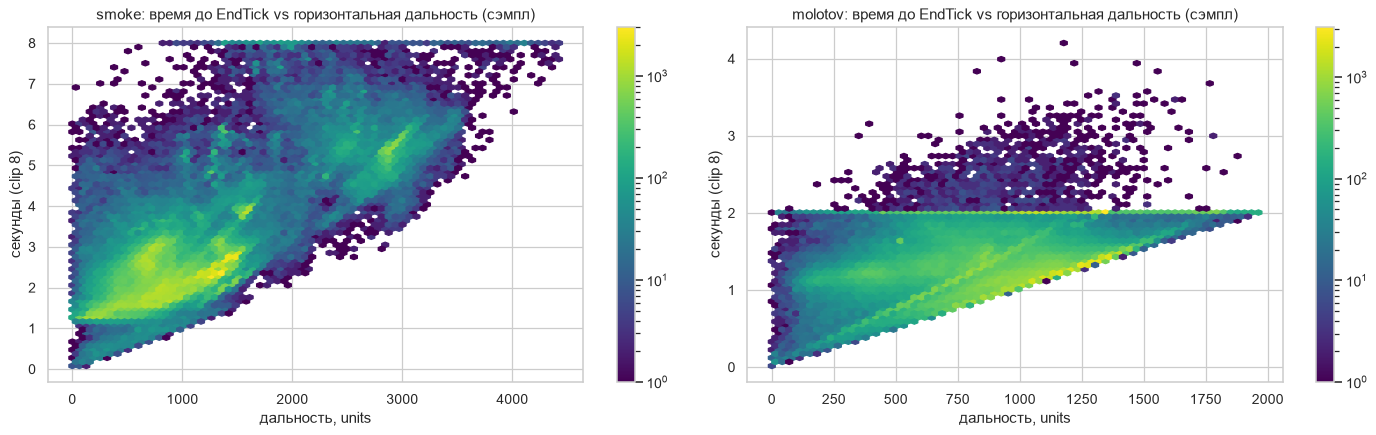

smoke    Spearman(дальность, время полёта) = 0.656
molotov  Spearman(дальность, время полёта) = 0.450
flash    Spearman(дальность, время полёта) = 0.013
he       Spearman(дальность, время полёта) = 0.014


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (gt, d) in zip(axes, [('smoke', sm), ('molotov', mo)]):
    s = d.sample(min(len(d), 300_000), random_state=4)
    hb = ax.hexbin(s['throw_dist'], s['flight_s'].clip(upper=8), gridsize=70, bins='log', cmap='viridis', mincnt=1)
    fig.colorbar(hb, ax=ax)
    ax.set_title(f'{gt}: время до EndTick vs горизонтальная дальность (сэмпл)'); ax.set_xlabel('дальность, units'); ax.set_ylabel('секунды (clip 8)')
plt.tight_layout(); plt.show()
for gt, d in [('smoke', sm), ('molotov', mo), ('flash', fb), ('he', he)]:
    print(f"{gt:8s} Spearman(дальность, время полёта) = {stats.spearmanr(d['throw_dist'], d['flight_s']).statistic:.3f}")

У смока и молотова время до `EndTick` растёт с дальностью: снаряду нужно долететь и остановиться. У флешки и HE связи нет,
потому что время фиксировано фитилём. У молотова видна «полка» на ~2 с: гранаты, сгоревшие в воздухе, так и не долетели до цели.

## 4. Корреляционные матрицы по типам гранат
Используем Spearman, потому что многие признаки бимодальные или с тяжёлыми хвостами. Считаем на всех бросках каждого типа.

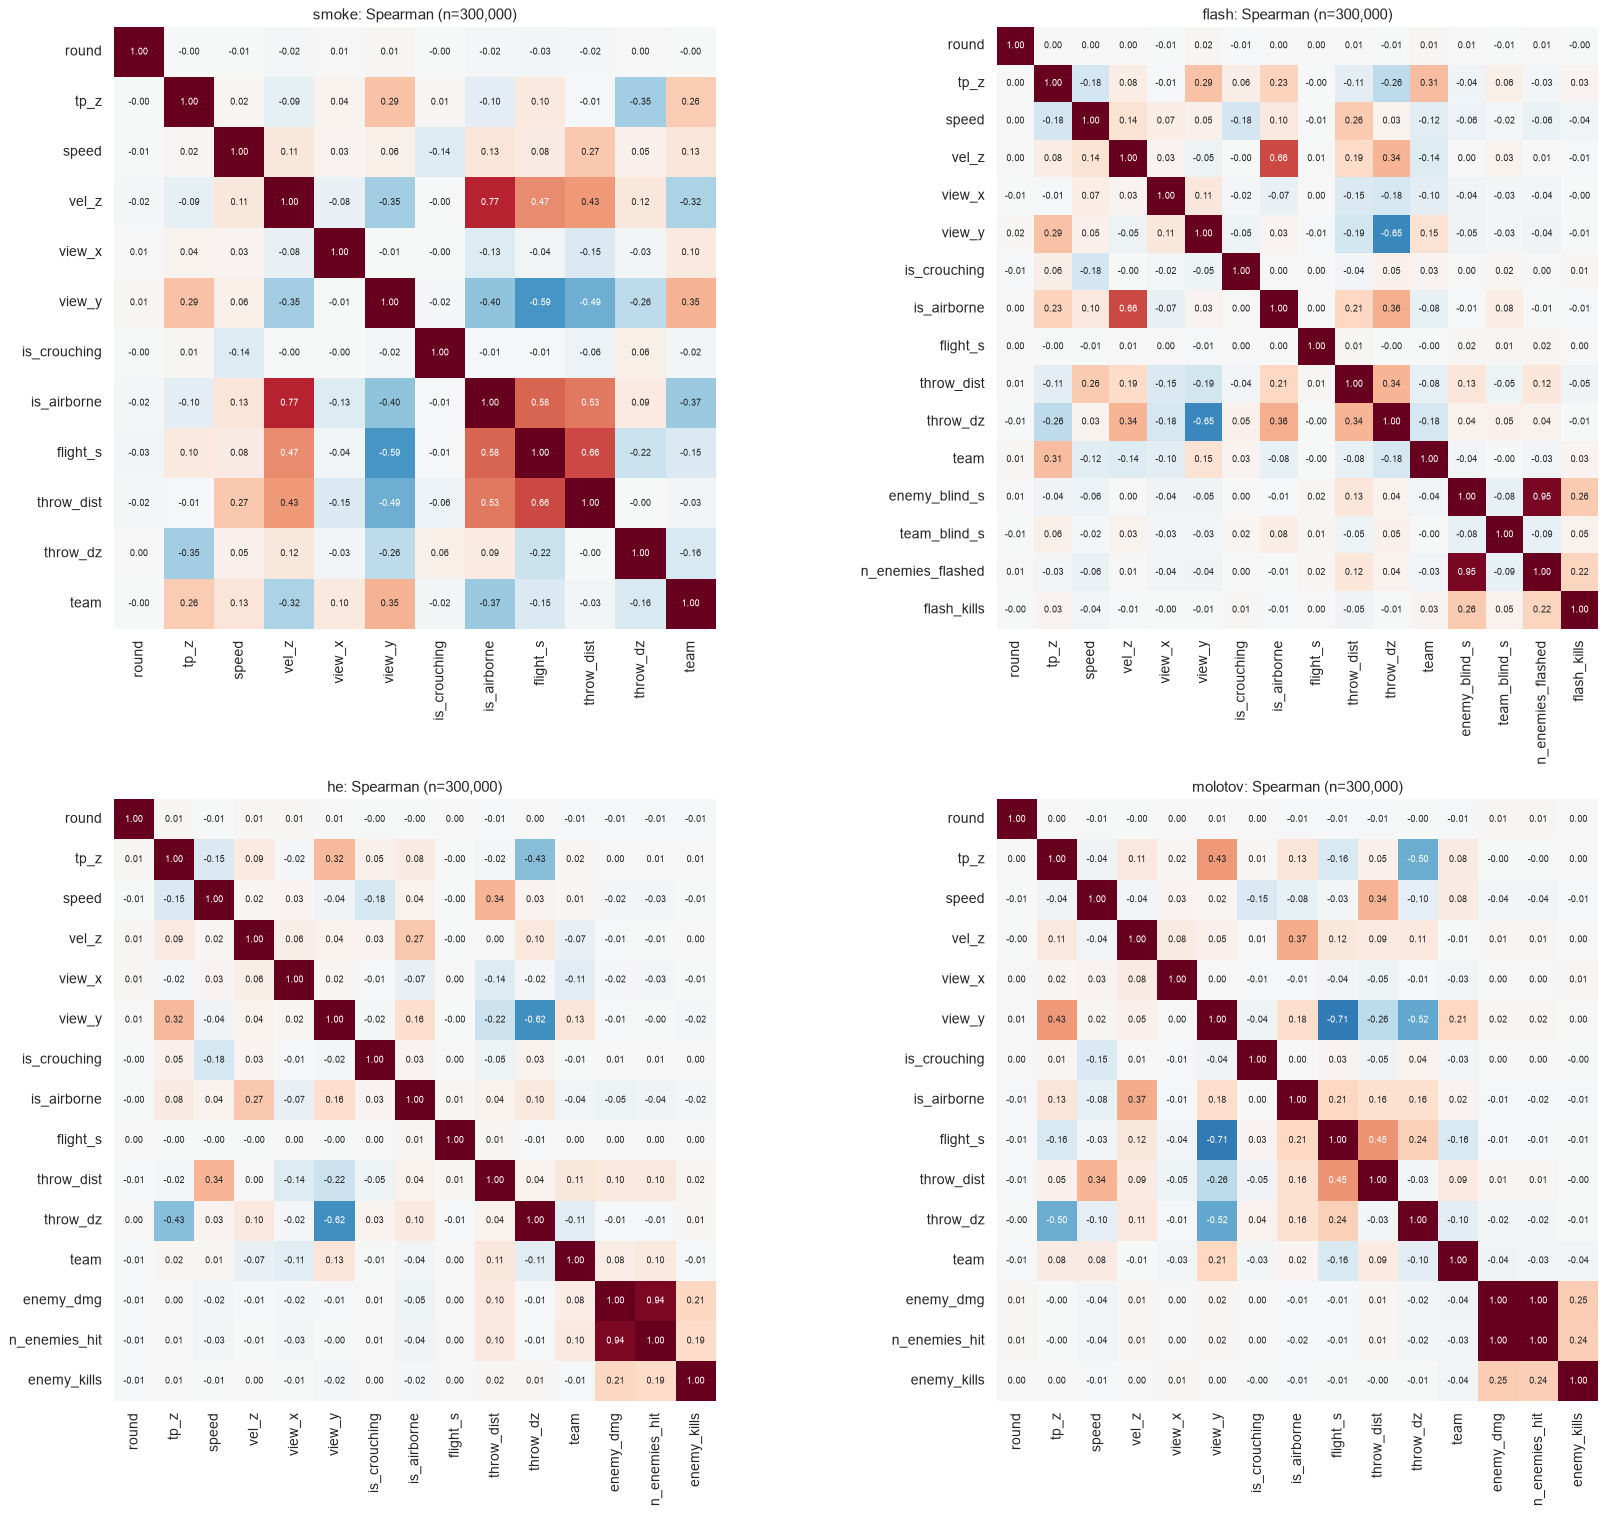

In [31]:
base_cols = ['round', 'tp_z', 'speed', 'vel_z', 'view_x', 'view_y', 'is_crouching', 'is_airborne', 'flight_s', 'throw_dist', 'throw_dz', 'team']
outcome = {'smoke': [], 'flash': ['enemy_blind_s', 'team_blind_s', 'n_enemies_flashed', 'flash_kills'],
           'he': ['enemy_dmg', 'n_enemies_hit', 'enemy_kills'], 'molotov': ['enemy_dmg', 'n_enemies_hit', 'enemy_kills']}
fig, axes = plt.subplots(2, 2, figsize=(20, 17))
for ax, gt in zip(axes.ravel(), GT_ORDER):
    d = throws.loc[throws['grenade_type'] == gt, base_cols + outcome[gt]].astype('float64')
    d = d.sample(min(len(d), 300_000), random_state=5)  # Spearman на 300k ≈ точен до 3-го знака
    c = d.corr(method='spearman')
    sns.heatmap(c, ax=ax, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, square=True, cbar=False)
    ax.set_title(f'{gt}: Spearman (n={len(d):,})')
plt.tight_layout(); plt.show()

- `team` коррелирует с `tp_z` (+0.26…0.31 у смоков и флешек) и с `view_y`/`is_airborne` у смоков: CT бросают с возвышений,
  а T чаще делают прыжковые лайнапы с прицелом вверх.
- `view_y` ↔ `throw_dist`/`flight_s` отрицательная (у смоков −0.49/−0.59, у молотовов −0.26/−0.71): чем выше прицел (отрицательный pitch),
  тем дальше и дольше летит граната. Это классический лайнап. У смоков к этому добавляются `is_airborne`/`vel_z` ↔ дальность (+0.53): jump-throw.
- У флешек и HE `view_y` ↔ `throw_dz` ≈ −0.62…−0.65: броском вверх закидывают на верхние ярусы.
- Эффективность HE и флешки почти не коррелирует ни с одним «параметром броска» по отдельности — она определяется местом,
  то есть парой «откуда → куда» (раздел 3.7), а не скоростью или стойкой.

## 5. Выводы

**Ключевые находки**
1. **Объём:** 2 385 417 бросков в 10 000 матчах (в 16 матчах гранат нет вовсе) на Cache, в среднем ~238 гранат за матч. Смоков больше всего, затем флешки, HE и молотовы.
   T бросают больше флешек, CT — больше молотовов и HE (оборона и задержка).
2. **Экономика по раундам:** в пистолетках (0, 12) гранат меньше всего (~3 на раунд против ~14 при полном закупе), в раундах 1 и 13 видно эко,
   к раундам 2–3 и 14–15 — полный закуп, перед сменой сторон (11, 23) — пик, в овертайме — максимум. Это косвенно восстанавливает экономику, которой в датасете нет.
3. **Физика подтверждена данными:** урон HE убывает от ~98 HP до 0 на ~350 units от `PosTo`; ослепление зависит от угла взгляда жертвы
   (полная засветка в FOV, короткая — спиной) и от расстояния. Значит, координаты и углы надёжны и пригодны для фич.
4. **Ошибки, которые можно измерить:** **52% всех ослеплений приходятся на своих** (29% — тиммейты, 23% — сам бросивший).
   На одну флешку в среднем ~1.9 с слепоты врагов и ~1.5 с слепоты своих. 63% HE не задевают ни одного врага.
   При этом 6.4% ослеплённых врагов погибают, пока ещё слепы, и половину таких убийств делает сам бросивший. Это готовая метрика flash-assist.
   Это прямые метрики для персональной обратной связи («ты ослепил своих на N секунд за матч»).
5. **Скилл:** с ростом рейтинга Premier растут и число гранат на игрока, и их эффективность (флешка: +29% слепых секунд врагов от <5k к 25–30k,
   HE: +20% урона), а слепота своих снижается. Этого достаточно для бенчмарка
   «ты против своего тира».
6. **Карта эффективности:** плотность и эффективность бросков сильно локализованы. Есть устойчивые точки «откуда → куда»
   с высоким средним уроном или ослеплением — основа для рекомендаций лайнапов на Cache.

**Ограничения датасета**
- Нет результата раунда и матча, счёта, экономики (денег, закупа, оружия) — эффект гранат на победу в раунде не измерить, эко восстанавливается только косвенно.
- Нет имён игроков и `MapName`; карта одна (Cache, распознана по координатам). На другие карты выводы по зонам не переносятся.
- **Смоки без исхода**: неизвестно, что смок перекрыл, и нет длительности. Оценить их можно только по точке приземления.
- `PremierRatingNew` заполнен только у ~24% игроков, есть пики на границах тиров. Разрезы по скиллу смещены к игрокам с видимым рейтингом.
- `StartProperVelocity` дублирует скорость игрока с обратным знаком, то есть начальной скорости снаряда нет.
  Траектории нет: есть только точки начала и конца.
- `ConvexHull3D` у молотовов почти всегда пуст, площадь и покрытие огня оценить нельзя.
- Нет callouts и радара. Зоны здесь — это сетка по координатам, без привязки к названиям точек.
- Нет позиций игроков вне событий гранат, поэтому, например, «сколько врагов было в зоне смока» не посчитать.